# Домашняя работа. scRNA-seq: HGSOC

| | |
|---|---|
| **Датасет** | GEO **GSE184880**. *Single-cell RNA sequencing reveals tissue architecture during human high-grade serous ovarian cancer progression* |


In [2]:
from pathlib import Path
import re
import gzip
import json
import tarfile
import urllib.parse
import urllib.request
import warnings

import numpy as np
import pandas as pd
import scipy.io
import scipy.sparse as sp
from scipy.stats import median_abs_deviation
import matplotlib.pyplot as plt
import scanpy as sc
import anndata as ad
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*not unique.*")
warnings.filterwarnings("ignore", category=DeprecationWarning)

SEED = 42
np.random.seed(SEED)
sc.settings.verbosity = 2
sc.settings.n_jobs = 8
sc.settings.set_figure_params(dpi=90, frameon=False, figsize=(5, 5), facecolor="white")

DATA_DIR = Path("data")
GEO_DIR = DATA_DIR / "GSE184880"          # сюда кладём GSE184880_RAW.tar
RAW_DIR = GEO_DIR / "raw"                 
RESULTS_DIR = Path("results")
for d in (GEO_DIR, RAW_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

INCLUDE_NORMAL = False   
USE_HARMONY = True       # интеграция образцов (пациенток) через Harmony

print("scanpy", sc.__version__, "| anndata", ad.__version__, "| numpy", np.__version__)

scanpy 1.11.5 | anndata 0.12.19 | numpy 2.4.6


### 0.1. Образцы

В серии 12 образцов (10x Genomics, Illumina NovaSeq 6000): 5 образцов нормальной ткани яичника и 7 опухолей HGSOC. Для ДЗ берём **7 опухолей**

In [3]:
SAMPLES = pd.DataFrame({
    "gsm": [f"GSM55992{i}" for i in range(20, 32)],
    "sample": [f"Normal{i}" for i in range(1, 6)] + [f"HGSOC{i}" for i in range(1, 8)],
    "condition": ["Normal"] * 5 + ["Tumor"] * 7,
    "geo_title": [f"Normal ovarian tissue{i}" for i in range(1, 6)]
                 + [f"Cancer_HGSOC{i}" for i in range(1, 8)],
}).set_index("gsm")

use_samples = SAMPLES if INCLUDE_NORMAL else SAMPLES[SAMPLES["condition"] == "Tumor"]
display(use_samples)

,sample,condition,geo_title
gsm,,,
GSM5599225,HGSOC1,Tumor,Cancer_HGSOC1
GSM5599226,HGSOC2,Tumor,Cancer_HGSOC2
GSM5599227,HGSOC3,Tumor,Cancer_HGSOC3
GSM5599228,HGSOC4,Tumor,Cancer_HGSOC4
GSM5599229,HGSOC5,Tumor,Cancer_HGSOC5
GSM5599230,HGSOC6,Tumor,Cancer_HGSOC6
GSM5599231,HGSOC7,Tumor,Cancer_HGSOC7


### 0.2. Скачивание и распаковка



In [4]:
TAR_URL = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE184nnn/GSE184880/suppl/GSE184880_RAW.tar"
tar_path = GEO_DIR / "GSE184880_RAW.tar"


def safe_extract(archive, dest):
    dest.mkdir(parents=True, exist_ok=True)
    with tarfile.open(archive) as tar:
        try:
            tar.extractall(dest, filter="data")
        except TypeError:
            tar.extractall(dest)


def has_matrices(root):
    return any(root.rglob("*.mtx*")) or any(root.rglob("*.h5"))


if not has_matrices(GEO_DIR):
    if not tar_path.exists():
        print(f"Скачиваю {TAR_URL} ...")
        urllib.request.urlretrieve(TAR_URL, tar_path)
    print("Распаковываю", tar_path)
    safe_extract(tar_path, RAW_DIR)

# иногда внутри RAW.tar лежат архивы отдельных образцов, распаковываем и их
for inner in sorted(GEO_DIR.rglob("*.tar*")) + sorted(GEO_DIR.rglob("*.tgz")):
    if inner.resolve() == tar_path.resolve() or not re.search(r"\.(tar(\.gz)?|tgz)$", inner.name):
        continue
    target = inner.parent / re.sub(r"\.(tar(\.gz)?|tgz)$", "", inner.name)
    if not target.exists():
        safe_extract(inner, target)

files = sorted(str(p.relative_to(GEO_DIR)) for p in GEO_DIR.rglob("*")
               if p.is_file() and not p.name.endswith(".tar"))
print(f"Файлов: {len(files)}")
print("\n".join(files))

Распаковываю data/GSE184880/GSE184880_RAW.tar
Файлов: 36
raw/GSM5599220_Norm1.barcodes.tsv.gz
raw/GSM5599220_Norm1.genes.tsv.gz
raw/GSM5599220_Norm1.matrix.mtx.gz
raw/GSM5599221_Norm2.barcodes.tsv.gz
raw/GSM5599221_Norm2.genes.tsv.gz
raw/GSM5599221_Norm2.matrix.mtx.gz
raw/GSM5599222_Norm3.barcodes.tsv.gz
raw/GSM5599222_Norm3.genes.tsv.gz
raw/GSM5599222_Norm3.matrix.mtx.gz
raw/GSM5599223_Norm4.barcodes.tsv.gz
raw/GSM5599223_Norm4.genes.tsv.gz
raw/GSM5599223_Norm4.matrix.mtx.gz
raw/GSM5599224_Norm5.barcodes.tsv.gz
raw/GSM5599224_Norm5.genes.tsv.gz
raw/GSM5599224_Norm5.matrix.mtx.gz
raw/GSM5599225_Cancer1.barcodes.tsv.gz
raw/GSM5599225_Cancer1.genes.tsv.gz
raw/GSM5599225_Cancer1.matrix.mtx.gz
raw/GSM5599226_Cancer2.barcodes.tsv.gz
raw/GSM5599226_Cancer2.genes.tsv.gz
raw/GSM5599226_Cancer2.matrix.mtx.gz
raw/GSM5599227_Cancer3.barcodes.tsv.gz
raw/GSM5599227_Cancer3.genes.tsv.gz
raw/GSM5599227_Cancer3.matrix.mtx.gz
raw/GSM5599228_Cancer4.barcodes.tsv.gz
raw/GSM5599228_Cancer4.genes.tsv.gz
ra

### 0.3. Чтение матриц



In [5]:
def classify_file(path):
    name = path.name.lower()
    if name.endswith(".h5"):
        return "h5"
    if ".mtx" in name:
        return "matrix"
    if "barcode" in name:
        return "barcodes"
    if "feature" in name or "gene" in name:
        return "features"
    return None


def collect_sample_files(root):
    # {GSM: {"matrix": path, "barcodes": path, "features": path}}
    groups = {}
    for p in sorted(root.rglob("*")):
        if not p.is_file() or p.name.endswith((".tar", ".tgz", ".tar.gz")):
            continue
        m = re.search(r"GSM\d+", str(p.relative_to(root)))
        kind = classify_file(p)
        if m and kind:
            groups.setdefault(m.group(0), {})[kind] = p
    return groups


def read_table(path):
    sep = "," if ".csv" in path.name.lower() else "\t"
    return pd.read_csv(path, sep=sep, header=None, dtype=str)


def read_mtx_sample(files):
    if "h5" in files:
        a = sc.read_10x_h5(files["h5"])
        a.var_names_make_unique()
        return a
    missing = {"matrix", "barcodes", "features"} - set(files)
    if missing:
        raise FileNotFoundError(f"Не хватает файлов {missing}: {files}")

    opener = gzip.open if files["matrix"].name.endswith(".gz") else open
    with opener(files["matrix"], "rb") as fh:
        X = sp.csr_matrix(scipy.io.mmread(fh))
    barcodes = read_table(files["barcodes"])[0].to_numpy()
    feats = read_table(files["features"])

    dims = set(X.shape)
    if len(feats) - 1 in dims and len(feats) not in dims:        # строка-заголовок
        feats = feats.iloc[1:].reset_index(drop=True)
    if len(barcodes) - 1 in dims and len(barcodes) not in dims:
        barcodes = barcodes[1:]
    if X.shape != (len(feats), len(barcodes)) and X.shape == (len(barcodes), len(feats)):
        X = X.T.tocsr()                                           # записано как клетки × гены
    assert X.shape == (len(feats), len(barcodes)), \
        f"Размеры не совпадают: матрица {X.shape}, генов {len(feats)}, баркодов {len(barcodes)}"

    if feats.shape[1] >= 2:
        gene_ids, symbols = feats[0].to_numpy(), feats[1].to_numpy()
        if np.mean(pd.Series(symbols).str.startswith("ENSG")) > 0.5 > np.mean(pd.Series(gene_ids).str.startswith("ENSG")):
            gene_ids, symbols = symbols, gene_ids                  # столбцы перепутаны местами
    else:
        gene_ids = symbols = feats[0].to_numpy()

    var = pd.DataFrame({"gene_ids": gene_ids}, index=pd.Index(symbols))
    if feats.shape[1] >= 3:
        var["feature_types"] = feats[2].to_numpy()
    a = ad.AnnData(X=X.T.tocsr().astype(np.float32), obs=pd.DataFrame(index=barcodes), var=var)
    if "feature_types" in a.var and (a.var["feature_types"] == "Gene Expression").any():
        a = a[:, a.var["feature_types"] == "Gene Expression"].copy()
    a.var_names_make_unique()
    return a

In [6]:
groups = collect_sample_files(GEO_DIR)
print("GSM в архиве:", ", ".join(sorted(groups)))

adatas = []
for gsm, row in use_samples.iterrows():
    if gsm not in groups:
        print(f"!! Нет файлов для {gsm} ({row['sample']}), пропускаю")
        continue
    a = read_mtx_sample(groups[gsm])
    if a.n_obs > 30000:   # так выглядит raw-матрица со всеми каплями, а не отфильтрованная
        print(f"{row['sample']}: {a.n_obs} баркодов, похоже на raw-матрицу; оставляю баркоды с >= 500 UMI")
        sc.pp.filter_cells(a, min_counts=500)
    a.obs_names = [f"{row['sample']}_{bc}" for bc in a.obs_names]
    a.obs["sample"] = row["sample"]
    a.obs["gsm"] = gsm
    a.obs["condition"] = row["condition"]
    adatas.append(a)
    print(f"{gsm}  {row['sample']:>8}: {a.n_obs:6d} клеток × {a.n_vars} генов")

if len({a.n_vars for a in adatas}) > 1:
    print("!! Наборы генов различаются между образцами, берём пересечение (join='inner')")
adata = ad.concat(adatas, join="inner", merge="same")
adata.obs["sample"] = pd.Categorical(adata.obs["sample"],
                                     categories=[s for s in use_samples["sample"] if s in set(adata.obs["sample"])])
adata.obs["condition"] = adata.obs["condition"].astype("category")
adata.obs["gsm"] = adata.obs["gsm"].astype("category")
del adatas
adata

GSM в архиве: GSM5599220, GSM5599221, GSM5599222, GSM5599223, GSM5599224, GSM5599225, GSM5599226, GSM5599227, GSM5599228, GSM5599229, GSM5599230, GSM5599231
GSM5599225    HGSOC1:   8823 клеток × 27984 генов
GSM5599226    HGSOC2:   4390 клеток × 27984 генов
GSM5599227    HGSOC3:   5107 клеток × 27984 генов
GSM5599228    HGSOC4:   4169 клеток × 27984 генов
GSM5599229    HGSOC5:   5892 клеток × 27984 генов
GSM5599230    HGSOC6:   5215 клеток × 27984 генов
GSM5599231    HGSOC7:   5179 клеток × 27984 генов


AnnData object with n_obs × n_vars = 38775 × 27984
    obs: 'sample', 'gsm', 'condition'
    var: 'gene_ids', 'feature_types'

---
## Задание 1. Данные и контроль качества

### 1.1. Описание данных

- **Ткань.** Первичные опухоли яичника 7 пациенток с **HGSOC**, не получавших лечения, на ранних и поздних стадиях, а также 5 образцов неопухолевой ткани яичника от женщин сопоставимого возраста. Ткань диссоциировали до суспензии отдельных клеток и обогащали живыми клетками (MACS Dead Cell Removal Kit). Библиотеки готовили на 10x Genomics Chromium и секвенировали на Illumina NovaSeq 6000.
- **Биологический вопрос.** Авторы описывали клеточную гетерогенность HGSOC и её микроокружения (опухолевые, иммунные, стромальные клетки) и то, как состав меняется с прогрессией (ранние vs поздние стадии). Основные выводы статьи:
  - в опухолевых клетках выражена EMT-сигнатура;
  - доминирующий тип CAF — «матриксные» CAF (mCAF: α-SMA, COL3A1, COL10A1, MMP11), которые индуцируют EMT;
  - в ранних опухолях обогащены M1-макрофаги C7-APOBEC3A, CD8⁺ TRM и истощённые CD8⁺ TEX с высокой экспрессией TIGIT.
- **Объём.** По данным авторов, 59 324 клетки во всех 12 образцах. Сколько клеток и генов в выбранных нами образцах, показывает ячейка ниже.

In [7]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.match(r"^(RP[SL]\d+[A-Z]?\d*|RPLP\d)$")
adata.var["hb"] = adata.var_names.str.match(r"^HB[ABDEGMQZ]\d?$")
print("Митохондриальных генов:", adata.var["mt"].sum(),
      "| рибосомных:", adata.var["ribo"].sum(), "| гемоглобиновых:", adata.var["hb"].sum())

sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], percent_top=[20],
                           log1p=True, inplace=True)

per_sample = adata.obs.groupby("sample", observed=True).agg(
    n_cells=("total_counts", "size"),
    median_UMI=("total_counts", "median"),
    median_genes=("n_genes_by_counts", "median"),
    median_pct_mt=("pct_counts_mt", "median"),
).round(1)
display(per_sample)
print(f"Всего до фильтрации: {adata.n_obs} клеток, {adata.n_vars} генов")
cells_raw = adata.obs["sample"].value_counts().sort_index()
n_genes_raw = adata.n_vars

Митохондриальных генов: 13 | рибосомных: 85 | гемоглобиновых: 10


,n_cells,median_UMI,median_genes,median_pct_mt
sample,,,,
HGSOC1,8823,6242.0,2059.0,13.900000
HGSOC2,4390,8884.0,2621.5,13.900000
HGSOC3,5107,4702.0,1739.0,7.000000
HGSOC4,4169,7285.0,1813.0,32.400002
HGSOC5,5892,4281.0,1627.0,7.100000
HGSOC6,5215,9427.0,2846.0,8.100000
HGSOC7,5179,3614.0,1347.0,7.100000


Всего до фильтрации: 38775 клеток, 27984 генов


### 1.2. Распределения метрик QC

- `total_counts`: число UMI в клетке, то есть размер библиотеки.
- `n_genes_by_counts`: число генов с ненулевой экспрессией, то есть сложность библиотеки.
- `pct_counts_mt`: доля UMI митохондриальных генов. Высокая доля говорит о повреждённой мембране: цитоплазматическая мРНК утекла, а митохондриальная осталась внутри органелл.
- Дополнительно смотрим `pct_counts_in_top_20_genes` (низкая сложность библиотеки), а также `pct_counts_ribo` и `pct_counts_hb` (примесь эритроцитов).

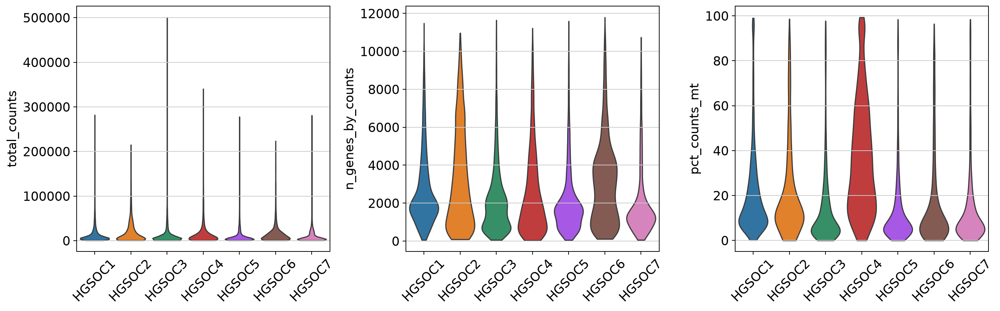

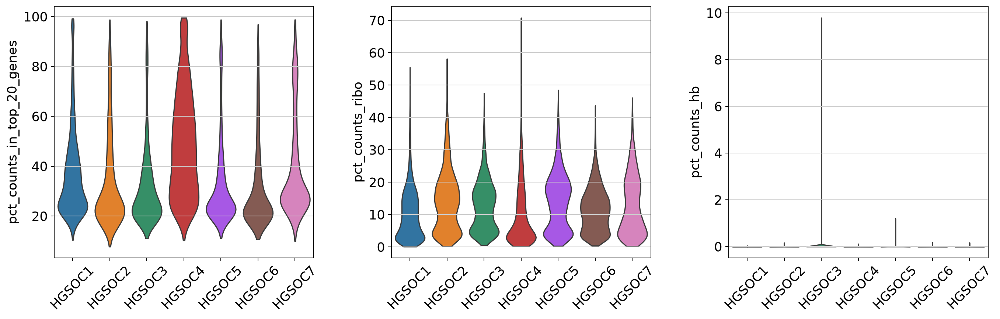

In [8]:
sc.pl.violin(adata, ["total_counts", "n_genes_by_counts", "pct_counts_mt"],
             groupby="sample", stripplot=False, rotation=45)
sc.pl.violin(adata, ["pct_counts_in_top_20_genes", "pct_counts_ribo", "pct_counts_hb"],
             groupby="sample", stripplot=False, rotation=45)

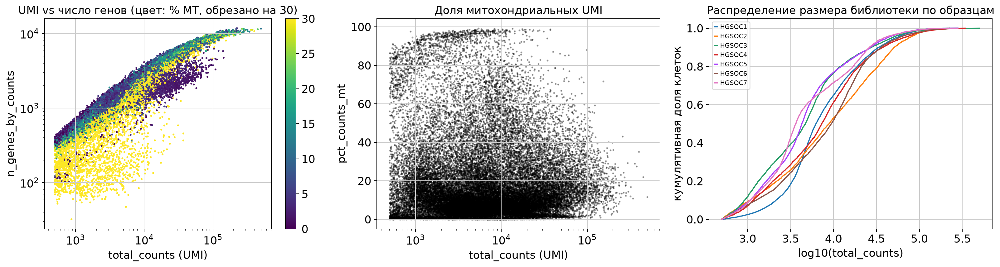

In [9]:
obs = adata.obs
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sca = axes[0].scatter(obs["total_counts"], obs["n_genes_by_counts"],
                      c=obs["pct_counts_mt"].clip(upper=30), s=2, cmap="viridis", rasterized=True)
axes[0].set(xscale="log", yscale="log", xlabel="total_counts (UMI)", ylabel="n_genes_by_counts",
            title="UMI vs число генов (цвет: % MT, обрезано на 30)")
plt.colorbar(sca, ax=axes[0])
axes[1].scatter(obs["total_counts"], obs["pct_counts_mt"], s=2, alpha=0.3, c="k", rasterized=True)
axes[1].set(xscale="log", xlabel="total_counts (UMI)", ylabel="pct_counts_mt",
            title="Доля митохондриальных UMI")
for s in obs["sample"].cat.categories:
    x = np.sort(np.log10(obs.loc[obs["sample"] == s, "total_counts"]))
    axes[2].plot(x, np.linspace(0, 1, len(x)), label=s)
axes[2].set(xlabel="log10(total_counts)", ylabel="кумулятивная доля клеток",
            title="Распределение размера библиотеки по образцам")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 1.3. Пороги фильтрации и их обоснование

| Фильтр | Порог | Кого исключаем |
|---|---|---|
| Абсолютный минимум | `n_genes_by_counts ≥ 200`, `total_counts ≥ 500` | пустые капли с фоновой (ambient) РНК, фрагменты разрушенных клеток |
| Размер библиотеки | `log1p(total_counts)` в пределах медиана ± 5 MAD **внутри образца** | снизу: клетки низкого качества; сверху: вероятные дублеты и мультиплеты |
| Число генов | `log1p(n_genes_by_counts)` в пределах медиана ± 5 MAD внутри образца | то же |
| Сложность библиотеки | `pct_counts_in_top_20_genes ≤` медиана + 5 MAD | клетки, у которых почти все UMI приходятся на несколько генов (умирающие клетки, артефакты) |
| Митохондрии | `pct_counts_mt ≤ 20 %` | клетки с повреждённой мембраной |
| Гены | ген детектирован в ≥ 3 клетках | гены, которые почти не встречаются и не несут информации, но шумят |
| Дублеты | Scrublet, отдельно для каждого образца | две клетки в одной капле: дают ложные «промежуточные» кластеры |

**Почему такие пороги.**
1. **Адаптивные пороги (MAD) вместо единых.** Образцы различаются по глубине секвенирования и составу. Единый порог по UMI выбросил бы непропорционально много клеток из «мелкого» образца и пропустил бы дублеты в «глубоком». MAD устойчив к выбросам. 5 MAD — мягкий порог, рекомендованный в *sc-best-practices* (Heumos et al., *Nat Rev Genet* 2023): отсекаются только явные выбросы, а редкие, но реальные популяции с малым размером библиотеки (например, нейтрофилы) остаются.
2. **20 % MT.** Для тканей человека в целом рекомендуют около 10 % (Osorio & Cai, *Bioinformatics* 2021). Но опухолевые клетки метаболически активны и в норме содержат больше митохондриальных транскриптов, поэтому в работах по солидным опухолям обычно берут 15–25 %. Иначе теряется заметная доля злокачественных клеток. Кроме того, авторы уже удаляли мёртвые клетки магнитным сортингом. Значение 20 % проверяем на графиках: отсекаемые клетки должны лежать в «хвосте» распределения и иметь низкую сложность библиотеки.
3. **Порог по `n_genes` сверху нужен вместе со Scrublet**, а не вместо него: гомотипические дублеты (две опухолевые клетки) Scrublet находит плохо, зато они видны по аномально большому размеру библиотеки.

Пороги, применённые в каждом образце:


,UMI_min,UMI_max,genes_min,genes_max,top20_max_%
sample,,,,,
HGSOC1,500,1.554759e+05,213.2,19807.3,77.0
HGSOC2,500,1.844486e+06,200.0,105325.4,63.0
HGSOC3,500,3.716375e+05,200.0,35864.5,59.7
HGSOC4,500,6.045438e+05,200.0,73078.8,127.8
HGSOC5,500,1.679271e+05,200.0,16055.9,52.1
HGSOC6,500,5.618424e+05,200.0,44206.4,52.7
HGSOC7,500,1.994035e+05,200.0,10699.2,65.9


Сколько клеток отсекает каждый фильтр (клетка может попасть под несколько):


,low_absolute,counts_MAD,genes_MAD,top20_MAD,high_MT,удалено_всего,доля_удалённых
sample,,,,,,,
HGSOC1,135,15,141,422,3059,3107,0.352
HGSOC2,156,0,0,442,1493,1493,0.340
HGSOC3,120,4,6,399,1051,1206,0.236
HGSOC4,211,0,1,0,2849,2871,0.689
HGSOC5,124,11,107,747,1086,1415,0.240
HGSOC6,102,0,69,658,1192,1209,0.232
HGSOC7,109,3,93,819,954,1481,0.286


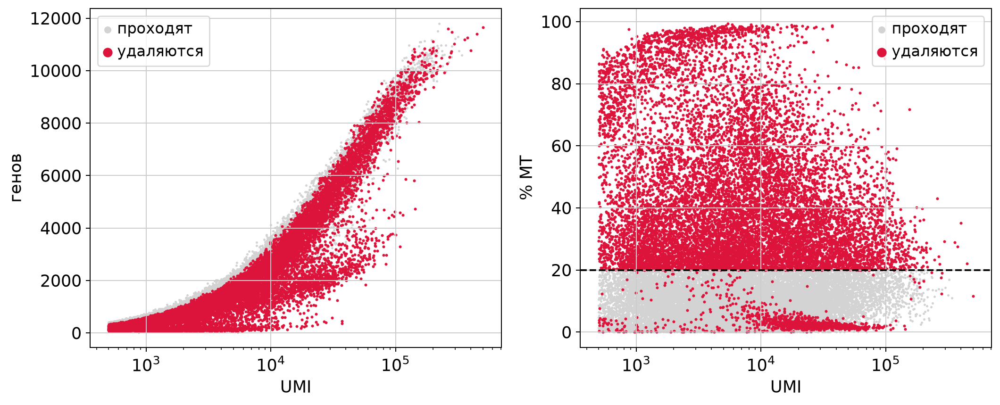

In [10]:
MIN_GENES = 200
MIN_COUNTS = 500
N_MADS = 5
MAX_PCT_MT = 20
MIN_CELLS_PER_GENE = 3


def mad_bounds(x, n_mads):
    med, mad = np.median(x), median_abs_deviation(x)
    return med - n_mads * mad, med + n_mads * mad


reasons = pd.DataFrame(False, index=adata.obs_names,
                       columns=["low_absolute", "counts_MAD", "genes_MAD", "top20_MAD", "high_MT"])
thr_rows = []
for s, o in adata.obs.groupby("sample", observed=True):
    c_lo, c_hi = mad_bounds(o["log1p_total_counts"], N_MADS)
    g_lo, g_hi = mad_bounds(o["log1p_n_genes_by_counts"], N_MADS)
    _, t_hi = mad_bounds(o["pct_counts_in_top_20_genes"], N_MADS)
    reasons.loc[o.index, "low_absolute"] = (o["n_genes_by_counts"] < MIN_GENES) | (o["total_counts"] < MIN_COUNTS)
    reasons.loc[o.index, "counts_MAD"] = (o["log1p_total_counts"] < c_lo) | (o["log1p_total_counts"] > c_hi)
    reasons.loc[o.index, "genes_MAD"] = (o["log1p_n_genes_by_counts"] < g_lo) | (o["log1p_n_genes_by_counts"] > g_hi)
    reasons.loc[o.index, "top20_MAD"] = o["pct_counts_in_top_20_genes"] > t_hi
    thr_rows.append({"sample": s,
                     "UMI_min": max(np.expm1(c_lo), MIN_COUNTS), "UMI_max": np.expm1(c_hi),
                     "genes_min": max(np.expm1(g_lo), MIN_GENES), "genes_max": np.expm1(g_hi),
                     "top20_max_%": t_hi})
reasons["high_MT"] = adata.obs["pct_counts_mt"] > MAX_PCT_MT
adata.obs["qc_pass"] = ~reasons.any(axis=1)

print("Пороги, применённые в каждом образце:")
display(pd.DataFrame(thr_rows).set_index("sample").round(1))
print("Сколько клеток отсекает каждый фильтр (клетка может попасть под несколько):")
removed = reasons.groupby(adata.obs["sample"], observed=True).sum()
removed["удалено_всего"] = (~adata.obs["qc_pass"]).groupby(adata.obs["sample"], observed=True).sum()
removed["доля_удалённых"] = (removed["удалено_всего"] / cells_raw).round(3)
display(removed)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ok = adata.obs["qc_pass"]
for ax, (x, y, xl, yl) in zip(axes, [("total_counts", "n_genes_by_counts", "UMI", "генов"),
                                     ("total_counts", "pct_counts_mt", "UMI", "% MT")]):
    ax.scatter(obs.loc[ok, x], obs.loc[ok, y], s=1, c="lightgrey", label="проходят", rasterized=True)
    ax.scatter(obs.loc[~ok, x], obs.loc[~ok, y], s=2, c="crimson", label="удаляются", rasterized=True)
    ax.set(xscale="log", xlabel=xl, ylabel=yl)
    ax.legend(markerscale=5)
axes[1].axhline(MAX_PCT_MT, ls="--", c="k")
plt.tight_layout()
plt.show()

In [11]:
adata = adata[adata.obs["qc_pass"]].copy()
sc.pp.filter_genes(adata, min_cells=MIN_CELLS_PER_GENE)
cells_after_qc = adata.obs["sample"].value_counts().sort_index()
print(f"После QC-фильтров: {adata.n_obs} клеток, {adata.n_vars} генов")

filtered out 6078 genes that are detected in less than 3 cells
После QC-фильтров: 25993 клеток, 21906 генов


### 1.4. Дублеты (Scrublet)

Scrublet (Wolock et al., *Cell Systems* 2019) симулирует искусственные дублеты, суммируя случайные пары клеток. Затем для каждой реальной клетки он оценивает, насколько её окружение в PCA-пространстве состоит из симулированных дублетов. Запускаем **отдельно для каждого образца** (`batch_key`), потому что дублеты возникают только внутри одной загрузки чипа. Запуск идёт на сырых каунтах, до нормализации.

Running Scrublet
filtered out 2870 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
Embedding transcriptomes using PCA...
    using data matrix X directly
Automatically set threshold at doublet score = 0.57
Detected doublet rate = 0.0%
Estimated detectable doublet fraction = 0.2%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 0.0%
filtered out 3081 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
Embedding transcriptomes using PCA...
    using data matrix X directly
Automatically set threshold at doublet score = 0.26
Detected doublet rate = 1.2%
Estimated detectable doublet f

,n_doublets,fraction
sample,,
HGSOC1,0,0.000
HGSOC2,35,0.012
HGSOC3,1,0.000
HGSOC4,8,0.006
HGSOC5,0,0.000
HGSOC6,48,0.012
HGSOC7,0,0.000


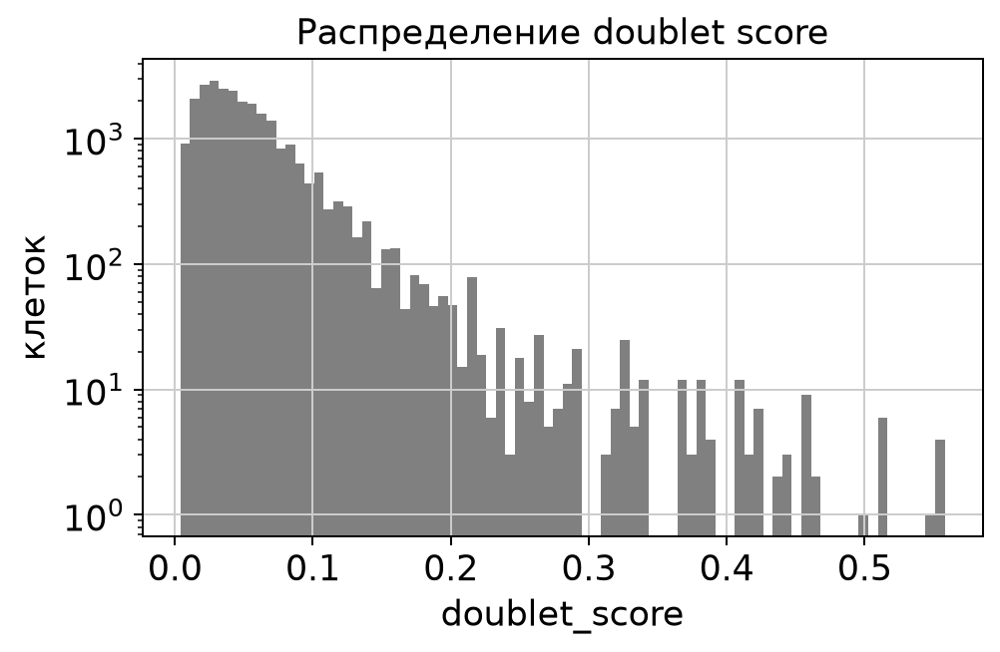

filtered out 11 genes that are detected in less than 3 cells


In [13]:
import importlib.util
sc.settings.n_jobs = 4 # костылечек костыль
if importlib.util.find_spec("skimage") is not None:
    sc.pp.scrublet(adata, batch_key="sample", random_state=SEED)       # порог подбирается автоматически
else:
    print("scikit-image не установлен (pip install scikit-image): Scrublet не может подобрать порог "
          "автоматически, используем фиксированный threshold=0.25")
    sc.pp.scrublet(adata, batch_key="sample", threshold=0.25, random_state=SEED)
dbl = adata.obs.groupby("sample", observed=True)["predicted_doublet"].agg(["sum", "mean"])
dbl.columns = ["n_doublets", "fraction"]
display(dbl.round(3))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(adata.obs["doublet_score"], bins=80, color="grey")
ax.set(xlabel="doublet_score", ylabel="клеток", yscale="log", title="Распределение doublet score")
plt.show()

adata = adata[~adata.obs["predicted_doublet"].astype(bool)].copy()
sc.pp.filter_genes(adata, min_cells=MIN_CELLS_PER_GENE)

In [14]:
qc_summary = pd.DataFrame({
    "до QC": cells_raw,
    "после фильтров QC": cells_after_qc,
    "после удаления дублетов": adata.obs["sample"].value_counts().sort_index(),
})
qc_summary.loc["Итого"] = qc_summary.sum()
qc_summary["осталось, %"] = (100 * qc_summary["после удаления дублетов"] / qc_summary["до QC"]).round(1)
display(qc_summary)
print(f"Гены: {n_genes_raw} → {adata.n_vars}")
print(f"Итого клеток для анализа: {adata.n_obs}")

,до QC,после фильтров QC,после удаления дублетов,"осталось, %"
sample,,,,
HGSOC1,8823,5716,5716,64.8
HGSOC2,4390,2897,2862,65.2
HGSOC3,5107,3901,3900,76.4
HGSOC4,4169,1298,1290,30.9
HGSOC5,5892,4477,4477,76.0
HGSOC6,5215,4006,3958,75.9
HGSOC7,5179,3698,3698,71.4
Итого,38775,25993,25901,66.8


Гены: 27984 → 21895
Итого клеток для анализа: 25901


**Что сделано и что получилось.** Метрики QC посчитаны для каждого образца, пороги выбраны адаптивно (5 MAD внутри образца) плюс жёсткие границы по минимуму генов и UMI и по доле MT. Затем удалены дублеты. Таблица выше показывает, сколько клеток и генов осталось. На scatter-графике удаляемые клетки (красные) лежат в «хвостах»: низкий UMI при высокой доле MT (повреждённые клетки) или аномально высокий UMI (дублеты).


---
## Задание 2. Нормализация и высоковариабельные гены

1. Сырые каунты сохраняем в `layers["counts"]`: они нужны для отбора HVG (`seurat_v3`) и повторного отбора HVG при субкластеризации.
2. `normalize_total(target_sum=1e4)` приводит все клетки к одному размеру библиотеки (CP10k), чтобы различия в глубине не выглядели биологическими.
3. `log1p` стабилизирует дисперсию и сжимает хвост очень высоких значений. Именно этот формат (log1p от CP10k, все гены) ожидает CellTypist.

In [15]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
print("Проверка: сумма expm1(X) по клетке ≈ 1e4 ->",
      np.round(np.expm1(adata.X[:5]).sum(axis=1).A1 if sp.issparse(adata.X) else np.expm1(adata.X[:5]).sum(axis=1)))

normalizing counts per cell
    finished (0:00:00)
Проверка: сумма expm1(X) по клетке ≈ 1e4 -> [10000. 10000. 10000. 10000. 10000.]


**Отбор HVG.** Используем `flavor="seurat_v3"` на сырых каунтах. Метод аппроксимирует зависимость log(дисперсии) от log(среднего) кривой loess и ранжирует гены по стандартизованной дисперсии, то есть показывает, насколько ген изменчивее, чем ожидается при его уровне экспрессии. С `batch_key="sample"` HVG выбираются в каждом образце отдельно, затем ранжируются по числу образцов, где ген оказался HVG. Так мы не берём гены, которые различаются только между пациентками.

extracting highly variable genes
Отобрано HVG: 2000 из 21895


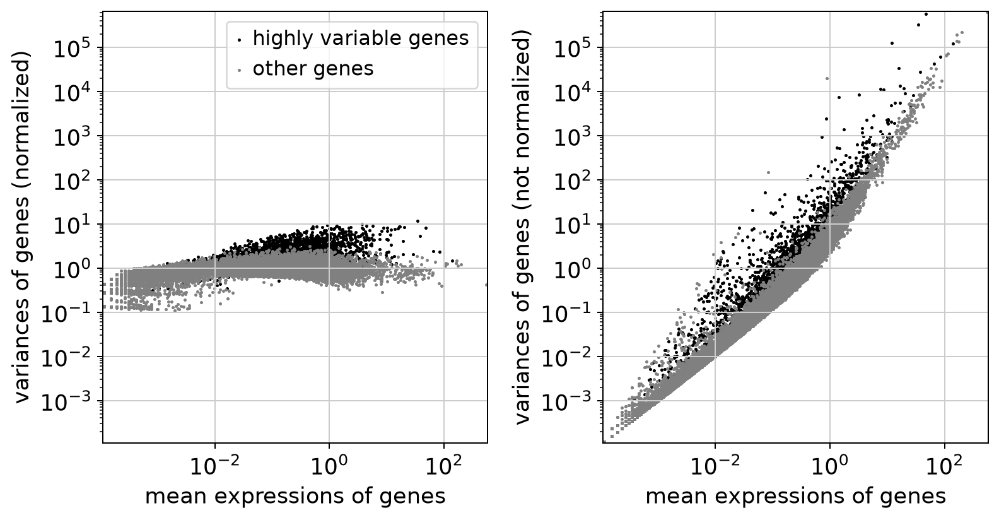

In [16]:
N_HVG = 2000
sc.pp.highly_variable_genes(adata, n_top_genes=N_HVG, flavor="seurat_v3",
                            layer="counts", batch_key="sample")
print("Отобрано HVG:", int(adata.var["highly_variable"].sum()), "из", adata.n_vars)
sc.pl.highly_variable_genes(adata, log=True)

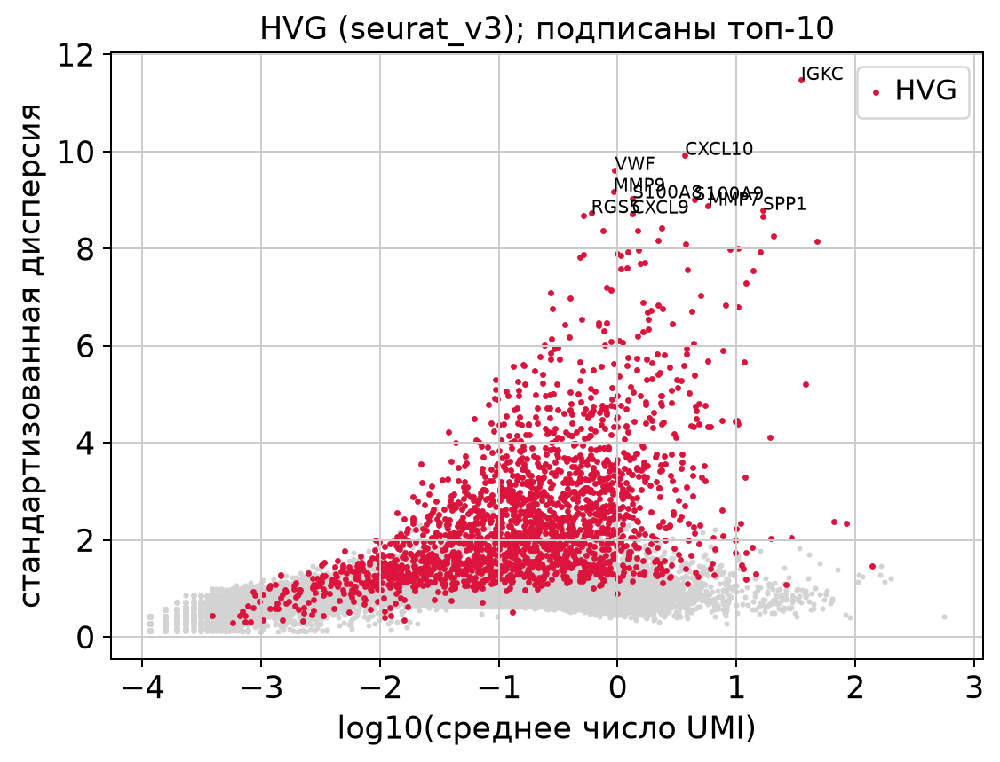

In [17]:
hvg_top10 = (adata.var[adata.var["highly_variable"]]
             .sort_values("variances_norm", ascending=False)
             .head(10))

v = adata.var
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(np.log10(v["means"] + 1e-6), v["variances_norm"], s=2, c="lightgrey", rasterized=True)
hv = v[v["highly_variable"]]
ax.scatter(np.log10(hv["means"] + 1e-6), hv["variances_norm"], s=3, c="crimson", rasterized=True, label="HVG")
for g, r in hvg_top10.iterrows():
    ax.annotate(g, (np.log10(r["means"] + 1e-6), r["variances_norm"]), fontsize=8)
ax.set(xlabel="log10(среднее число UMI)", ylabel="стандартизованная дисперсия",
       title="HVG (seurat_v3); подписаны топ-10")
ax.legend()
plt.show()

### 2.1. Топ-10 HVG и их функции

Описания берутся из NCBI Gene через MyGene.info (нужен интернет на сервере), а для частых в опухолях яичника генов добавлен комментарий на русском.

In [54]:
GENE_NOTES = { #Спасибо клодик
    # иммуноглобулины, плазматические клетки
    "IGKC": "константная область лёгкой κ-цепи Ig; маркер B/плазматических клеток",
    "IGHG1": "тяжёлая цепь IgG1; секретируется плазматическими клетками",
    "IGHG2": "тяжёлая цепь IgG2", "IGHG3": "тяжёлая цепь IgG3", "IGHG4": "тяжёлая цепь IgG4",
    "IGHA1": "тяжёлая цепь IgA1", "IGHM": "тяжёлая цепь IgM (наивные B, ранние плазмоциты)",
    "IGLC1": "лёгкая λ-цепь Ig", "IGLC2": "лёгкая λ-цепь Ig", "IGLC3": "лёгкая λ-цепь Ig",
    "JCHAIN": "J-цепь, полимеризация IgA/IgM; плазматические клетки",
    "MZB1": "шаперон сборки Ig в ЭПР; плазматические клетки",
    # строма и ECM
    "COL1A1": "коллаген I типа; фибробласты, CAF", "COL1A2": "коллаген I типа; фибробласты",
    "COL3A1": "коллаген III типа; фибробласты, mCAF", "COL11A1": "коллаген XI; маркер активированных CAF",
    "COL10A1": "коллаген X; mCAF (отмечен в статье)", "DCN": "декорин, протеогликан ECM; фибробласты",
    "LUM": "люмикан, протеогликан ECM; фибробласты", "POSTN": "периостин; CAF, ремоделирование матрикса",
    "SPARC": "остеонектин, матрицеллюлярный белок; строма/эндотелий",
    "MGP": "матриксный Gla-белок, ингибитор кальцификации; фибробласты",
    "FN1": "фибронектин; ECM, EMT", "BGN": "бигликан; CAF", "MMP11": "матриксная металлопротеиназа 11; mCAF",
    "CFD": "фактор комплемента D (адипсин); фибробласты", "APOD": "аполипопротеин D; фибробласты",
    "C7": "компонент комплемента C7; фибробласты", "SFRP4": "антагонист Wnt; фибробласты",
    "STAR": "транспорт холестерина в стероидогенезе; тека-клетки/строма яичника",
    "DLK1": "неканонический лиганд Notch; строма яичника",
    "IGFBP5": "IGF-связывающий белок 5; фибробласты", "CXCL14": "хемокин; фибробласты/эпителий",
    "ACTA2": "α-гладкомышечный актин (α-SMA); миофибробласты, перициты, mCAF",
    "TAGLN": "трансгелин; гладкомышечные клетки, миофибробласты", "RGS5": "регулятор G-белков; перициты",
    "MYH11": "тяжёлая цепь миозина ГМК; гладкомышечные клетки",
    # эндотелий
    "PLVAP": "белок диафрагм фенестр; эндотелий", "ACKR1": "рецептор DARC; эндотелий венул",
    "VWF": "фактор фон Виллебранда; эндотелий", "CCL21": "хемокин; лимфатический эндотелий/FRC",
    # эпителий и опухоль
    "EPCAM": "молекула адгезии эпителия", "KRT19": "кератин 19; эпителий", "KRT8": "кератин 8; простой эпителий",
    "KRT18": "кератин 18; простой эпителий", "KRT7": "кератин 7; мюллеров эпителий",
    "PAX8": "транскрипционный фактор мюллерова эпителия; маркер HGSOC",
    "WT1": "транскрипционный фактор; HGSOC, мезотелий, строма яичника",
    "MUC16": "CA-125, клинический маркер рака яичника", "WFDC2": "HE4, клинический маркер рака яичника",
    "MSLN": "мезотелин; HGSOC и мезотелий", "CP": "церулоплазмин; высоко в опухолевом эпителии",
    "SLPI": "ингибитор протеаз лейкоцитов; эпителий", "CLDN4": "клаудин-4, плотные контакты; эпителий",
    "CD24": "гликозилированный мембранный белок; опухолевый эпителий, B-клетки",
    "SPP1": "остеопонтин; TAM и опухолевые клетки", "MMP7": "матрилизин; опухолевый эпителий",
    "LCN2": "липокалин-2; эпителий при воспалении", "PI3": "элафин; эпителий",
    "IFI27": "интерферон-индуцируемый белок 27; ISG, высок в эпителии опухоли",
    "CRABP2": "связывание ретиноевой кислоты; опухолевый эпителий", "S100A1": "Ca-связывающий белок; эпителий",
    "MT1G": "металлотионеин; связывание металлов, стресс", "MT2A": "металлотионеин 2A",
    "TFF3": "трефоил-фактор 3; эпителий", "SCGB2A1": "маммаглобин B; секреторный эпителий",
    # миелоидные
    "LYZ": "лизоцим; моноциты/макрофаги", "S100A8": "кальпротектин (с S100A9); моноциты, нейтрофилы",
    "S100A9": "кальпротектин; моноциты, нейтрофилы", "C1QA": "компонент комплемента C1q; макрофаги",
    "C1QB": "C1q; макрофаги", "C1QC": "C1q; макрофаги", "APOE": "аполипопротеин E; TAM",
    "APOC1": "аполипопротеин C1; TAM", "CD74": "инвариантная цепь MHC II; APC",
    "HLA-DRA": "MHC II; антигенпрезентирующие клетки", "CXCL8": "IL-8, хемоаттрактант нейтрофилов",
    "IL1B": "провоспалительный цитокин IL-1β", "CCL3": "хемокин MIP-1α", "CCL4": "хемокин MIP-1β",
    "CXCL2": "хемокин; воспаление", "G0S2": "регулятор липолиза; нейтрофилы/моноциты",
    "CCL2": "MCP-1, привлечение моноцитов", "CXCL10": "IP-10, интерферон-индуцируемый хемокин",
    "TPSAB1": "триптаза; тучные клетки", "TPSB2": "триптаза; тучные клетки", "CPA3": "карбоксипептидаза A3; тучные клетки",
    # лимфоциты
    "CCL5": "RANTES; цитотоксические T и NK", "GNLY": "гранулизин; NK и цитотоксические T",
    "NKG7": "белок гранул NK/CTL", "GZMB": "гранзим B", "GZMK": "гранзим K; CD8 Tem",
    "CXCL13": "хемокин; истощённые/Tfh-подобные T, TLS", "IL7R": "рецептор IL-7; наивные/памяти T",
    "CCL19": "хемокин; FRC, зрелые DC", "FOXP3": "мастер-регулятор Treg",
    # прочее
    "HBB": "β-глобин; эритроциты (примесь)", "HBA1": "α-глобин; эритроциты", "HBA2": "α-глобин; эритроциты",
    "HSPA1A": "Hsp70; стресс-ответ (в т. ч. диссоциация)", "HSPA1B": "Hsp70", "FOS": "ранний ген ответа",
    "JUN": "ранний ген ответа", "EGR1": "ранний ген ответа", "MKI67": "Ki-67; пролиферация",
    "TOP2A": "топоизомераза IIα; G2/M", "PTGDS": "простагландин-D-синтаза; строма",
}


def fetch_gene_info(symbols):
    # краткое описание гена из NCBI Gene через MyGene.info; без интернета вернёт пустые строки
    out = {}
    for s in symbols:
        q = urllib.parse.urlencode({"q": f"symbol:{s}", "species": "human",
                                    "fields": "name,summary", "size": 1})
        try:
            with urllib.request.urlopen(f"https://mygene.info/v3/query?{q}", timeout=10) as r:
                hits = json.load(r).get("hits", [])
            h = hits[0] if hits else {}
            out[s] = (h.get("name", ""), (h.get("summary") or "")[:250])
        except Exception as e:
            out[s] = ("", f"(нет доступа к MyGene.info: {type(e).__name__})")
    return out


info = fetch_gene_info(hvg_top10.index)
top10_table = pd.DataFrame({
    "mean_UMI": hvg_top10["means"].round(2),
    "variances_norm": hvg_top10["variances_norm"].round(1),
    "в скольких образцах HVG": hvg_top10["highly_variable_nbatches"],
    "название (NCBI)": [info[g][0] for g in hvg_top10.index],
    "комментарий": [GENE_NOTES.get(g, "— (см. описание NCBI)") for g in hvg_top10.index],
    "описание (NCBI, сокращено)": [info[g][1] for g in hvg_top10.index],
})
with pd.option_context("display.max_colwidth", 120):
    display(top10_table)

,mean_UMI,variances_norm,в скольких образцах HVG,название (NCBI),комментарий,"описание (NCBI, сокращено)"
IGKC,34.80,11.5,7,immunoglobulin kappa constant,константная область лёгкой κ-цепи Ig; маркер B/плазматических клеток,Predicted to enable antigen binding activity and immunoglobulin receptor binding activity. Involved in retina homeos...
CXCL10,3.69,9.9,7,C-X-C motif chemokine ligand 10,"IP-10, интерферон-индуцируемый хемокин",This antimicrobial gene encodes a chemokine of the CXC subfamily and ligand for the receptor CXCR3. Binding of this ...
VWF,0.95,9.6,7,von Willebrand factor,фактор фон Виллебранда; эндотелий,This gene encodes a glycoprotein involved in hemostasis. The encoded preproprotein is proteolytically processed foll...
MMP9,0.92,9.2,7,matrix metallopeptidase 9,— (см. описание NCBI),Proteins of the matrix metalloproteinase (MMP) family are involved in the breakdown of extracellular matrix in norma...
S100A8,1.33,9.0,7,S100 calcium binding protein A8,"кальпротектин (с S100A9); моноциты, нейтрофилы",The protein encoded by this gene is a member of the S100 family of proteins containing 2 EF-hand calcium-binding mot...
S100A9,4.40,9.0,7,S100 calcium binding protein A9,"кальпротектин; моноциты, нейтрофилы",The protein encoded by this gene is a member of the S100 family of proteins containing 2 EF-hand calcium-binding mot...
MMP7,5.76,8.9,7,matrix metallopeptidase 7,матрилизин; опухолевый эпителий,This gene encodes a member of the peptidase M10 family of matrix metalloproteinases (MMPs). Proteins in this family ...
SPP1,16.66,8.8,7,secreted phosphoprotein 1,остеопонтин; TAM и опухолевые клетки,The protein encoded by this gene is involved in the attachment of osteoclasts to the mineralized bone matrix. The en...
RGS5,0.60,8.7,6,regulator of G protein signaling 5,регулятор G-белков; перициты,This locus represents naturally occurring readthrough transcription between the neighboring LOC127814295 (uncharacte...
CXCL9,1.32,8.7,7,C-X-C motif chemokine ligand 9,— (см. описание NCBI),This antimicrobial gene is part of a chemokine superfamily that encodes secreted proteins involved in immunoregulato...


**Интерпретация топ-10.** В опухолях обычно в топе оказываются гены, которые **очень сильно экспрессируются в одной популяции и почти не экспрессируются в остальных**:
- иммуноглобулины (`IGKC`, `IGHG1`, `JCHAIN`): плазматические клетки;
- коллагены и белки матрикса (`COL1A1`, `COL3A1`, `DCN`): фибробласты и CAF;
- маркеры опухолевого эпителия (`CP`, `WFDC2`, `MUC16`, `KRT19`);
- макрофагальные (`C1QA`, `APOE`, `SPP1`) и хемокины;
- `HBB`/`HBA`: примесь эритроцитов.

Поэтому HVG сами по себе подсказывают основные клеточные компартменты ткани.

**Вопрос: зачем выбирать HVG и почему не обязательно брать все гены для PCA и кластеризации?**
1. **Сигнал сосредоточен в небольшой части генов.** Из примерно 20–25 тыс. детектированных генов большинство либо почти не экспрессируются, либо экспрессируются одинаково во всех клетках (гены «домашнего хозяйства»). Их разброс между клетками — в основном технический шум пуассоновского сэмплирования UMI.
2. **Шум размывает структуру.** Если подать в PCA все гены, тысячи «шумных» генов суммарно дадут большую дисперсию, чем несколько сотен информативных, и первые компоненты будут хуже разделять типы клеток.
3. **Вычислительная эффективность.** PCA и граф на 2000 генах считаются быстрее и требуют меньше памяти.
4. **Ничего не теряем.** HVG только помечены (`adata.var["highly_variable"]`), все гены остаются в `adata.X`. Маркерный анализ, CellTypist и gene scores используют полный набор генов.
5. **Результат устойчив к числу HVG.** Значения в диапазоне 1000–5000 дают похожую кластеризацию; 2000 — стандартный компромисс.

---
## Задание 3. PCA, интеграция и кластеризация

PCA считаем по HVG на лог-нормализованных данных (`mask_var="highly_variable"`), как в семинаре и в текущем туториале scanpy.

computing PCA
    with n_comps=50
    finished (0:00:01)


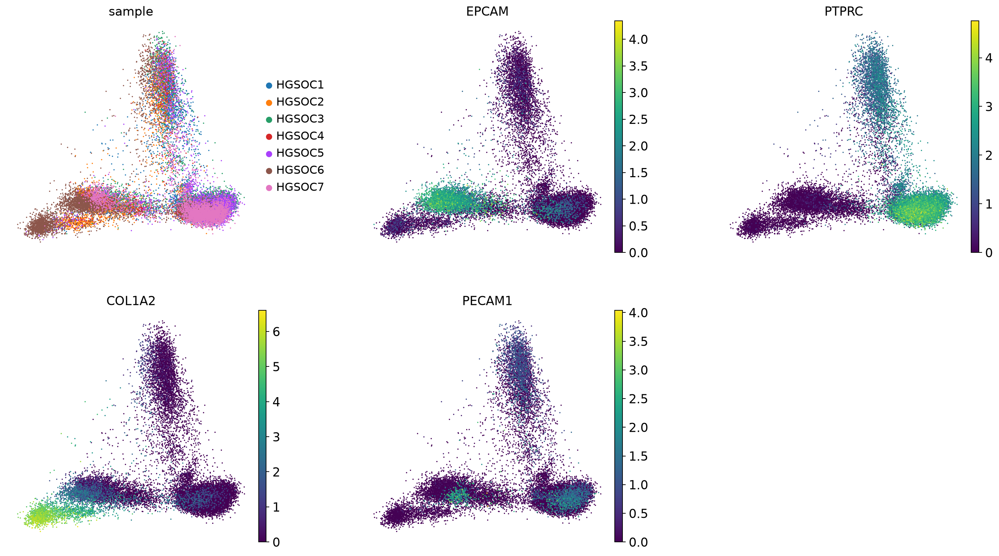

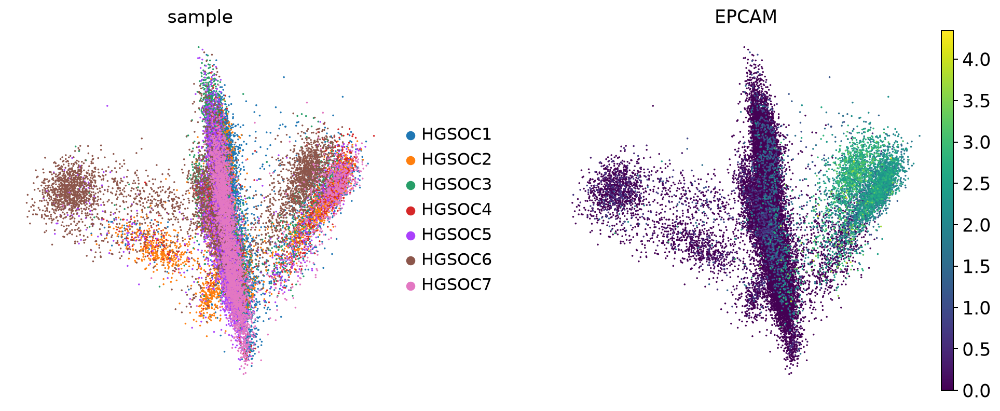

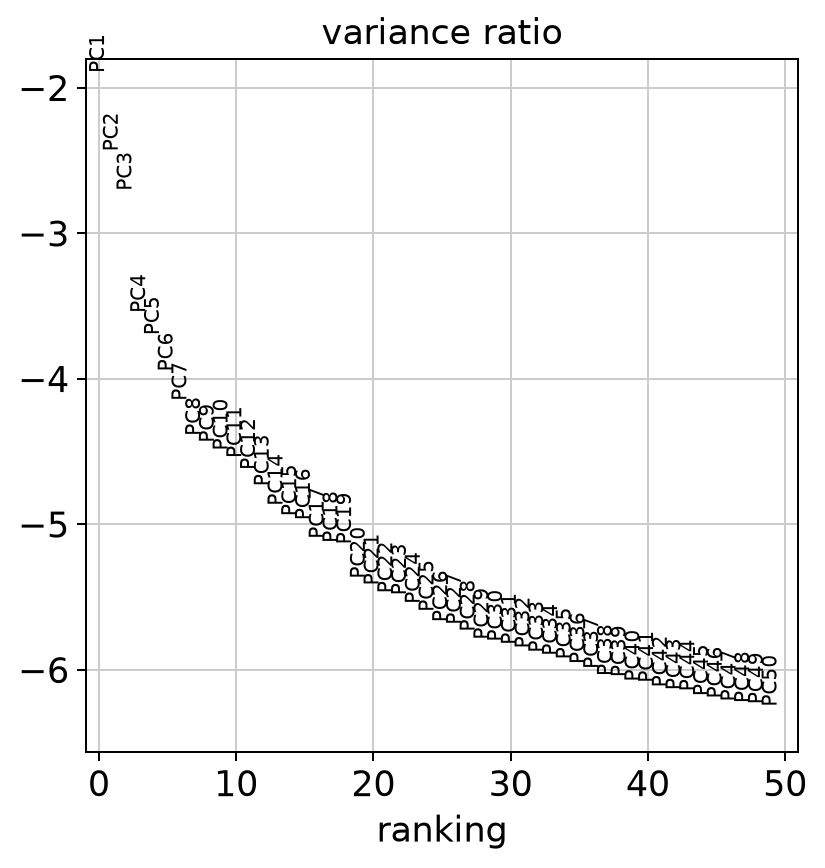

In [19]:
sc.tl.pca(adata, n_comps=50, mask_var="highly_variable", svd_solver="arpack", random_state=SEED)
pca_colors = ["sample"] + [g for g in ["EPCAM", "PTPRC", "COL1A2", "PECAM1"] if g in adata.var_names]
sc.pl.pca(adata, color=pca_colors, ncols=3, size=8, wspace=0.3)
sc.pl.pca(adata, color=pca_colors[:2], components=["3,4"], ncols=2, size=8, wspace=0.3)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

In [20]:
vr = adata.uns["pca"]["variance_ratio"]
noise_floor = np.median(vr[40:50])
elbow = int(np.argmax(vr < 1.2 * noise_floor))        # первая ГК, почти неотличимая от «шумового пола»
N_PCS = int(np.clip(elbow, 15, 40))
print(f"Доля дисперсии HVG, объяснённая 50 ГК: {vr.sum():.1%}")
print(f"«Локоть» (первая ГК с вкладом < 1.2 × медианы ГК 41–50): ГК{elbow}")
print(f"Берём N_PCS = {N_PCS}; эти ГК объясняют {vr[:N_PCS].sum():.1%} дисперсии")

Доля дисперсии HVG, объяснённая 50 ГК: 58.5%
«Локоть» (первая ГК с вкладом < 1.2 × медианы ГК 41–50): ГК37
Берём N_PCS = 37; эти ГК объясняют 55.7% дисперсии


На PCA-графике видно, что первые компоненты разделяют крупные компартменты ткани: эпителий (`EPCAM`), иммунные клетки (`PTPRC`), фибробласты (`COL1A2`), эндотелий (`PECAM1`). Число компонент выбрано по «локтю»: после него каждая следующая ГК объясняет почти столько же, сколько последние (шумовые) компоненты.

### 3.1. Интеграция образцов (Harmony)

Каждая опухоль — отдельная пациентка и отдельный запуск 10x, поэтому в данных есть **батч-эффект**. Кроме того, опухолевые клетки разных пациенток различаются по-настоящему (разные копийные аберрации). Без коррекции иммунные и стромальные клетки одного типа частично распадаются на кластеры «по пациенткам».

Harmony (Korsunsky et al., *Nat Methods* 2019) итеративно сдвигает клетки в PCA-пространстве так, чтобы в каждом мягком кластере были представлены все образцы. Результат записывается в `obsm["X_pca_harmony"]`, а исходный `X_pca` не меняется. Опухолевые клетки после интеграции всё равно частично остаются специфичными для пациенток, и это ожидаемо: это биология, а не техника.

In [21]:
def run_harmony(adata, key, n_pcs, basis="X_pca", out="X_pca_harmony"):
    import harmonypy
    X = np.asarray(adata.obsm[basis][:, :n_pcs], dtype=np.float64)
    meta = adata.obs[[key]].astype(str)
    ho = harmonypy.run_harmony(X, meta, [key], random_state=SEED, verbose=False)
    Z = np.asarray(ho.Z_corr)
    if Z.shape[0] != adata.n_obs:     # в разных версиях harmonypy Z_corr бывает (n_pcs × n_cells)
        Z = Z.T
    adata.obsm[out] = np.ascontiguousarray(Z, dtype=np.float32)
    return out


USE_REP = "X_pca"
if USE_HARMONY and adata.obs["sample"].nunique() > 1:
    try:
        USE_REP = run_harmony(adata, "sample", N_PCS)
        print("Harmony выполнен, дальше используем", USE_REP)
    except ImportError:
        print("harmonypy не установлен (pip install harmonypy), работаем без интеграции")
print("Представление для графа соседей:", USE_REP)

Harmony выполнен, дальше используем X_pca_harmony
Представление для графа соседей: X_pca_harmony


computing neighbors


/home/STUDY/FBMF/studfbmf01_12/software/miniforge/envs/sc_pbmc/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished (0:00:04)
computing UMAP
    finished (0:00:09)
computing neighbors
    finished (0:00:01)
computing UMAP
    finished (0:00:09)


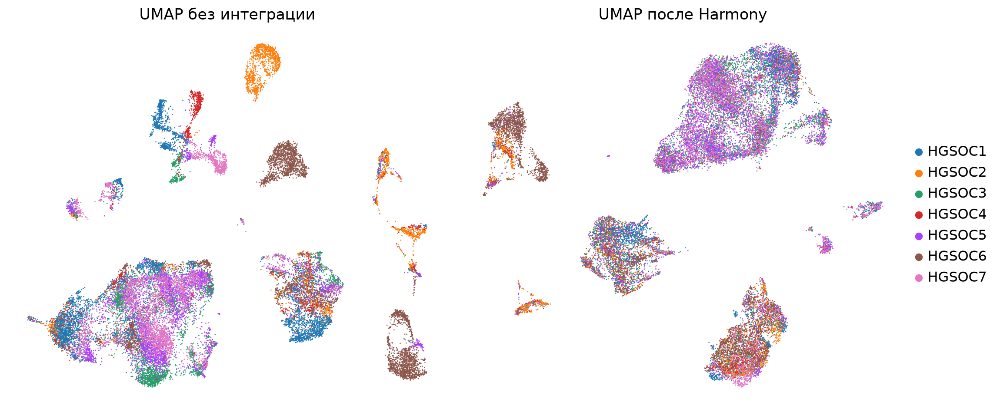

In [22]:
if USE_REP != "X_pca":
    # UMAP без интеграции, только для сравнения
    sc.pp.neighbors(adata, n_neighbors=15, n_pcs=N_PCS, use_rep="X_pca", key_added="pca_nn", random_state=SEED)
    sc.tl.umap(adata, neighbors_key="pca_nn", min_dist=0.3, random_state=SEED)
    adata.obsm["X_umap_uncorrected"] = adata.obsm["X_umap"].copy()
    del adata.obsp["pca_nn_connectivities"], adata.obsp["pca_nn_distances"], adata.uns["pca_nn"]

sc.pp.neighbors(adata, n_neighbors=15, use_rep=USE_REP,
                n_pcs=N_PCS if USE_REP == "X_pca" else None, random_state=SEED)
sc.tl.umap(adata, min_dist=0.3, random_state=SEED)

if "X_umap_uncorrected" in adata.obsm:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    sc.pl.embedding(adata, basis="X_umap_uncorrected", color="sample", ax=axes[0], show=False,
                    title="UMAP без интеграции", legend_loc=None)
    sc.pl.umap(adata, color="sample", ax=axes[1], show=False, title="UMAP после Harmony")
    plt.tight_layout()
    plt.show()

### 3.2. Кластеризация Leiden при двух разрешениях

Leiden максимизирует модулярность графа соседей. Параметр `resolution` (γ) задаёт «штраф» за крупные сообщества: чем больше γ, тем мельче кластеры. Используем `flavor="igraph"` (рекомендация scanpy ≥ 1.10, быстрее `leidenalg`) и фиксированный `random_state`.

running Leiden clustering
    finished (0:00:00)
resolution=0.3: 12 кластеров
running Leiden clustering
    finished (0:00:00)
resolution=1.0: 19 кластеров


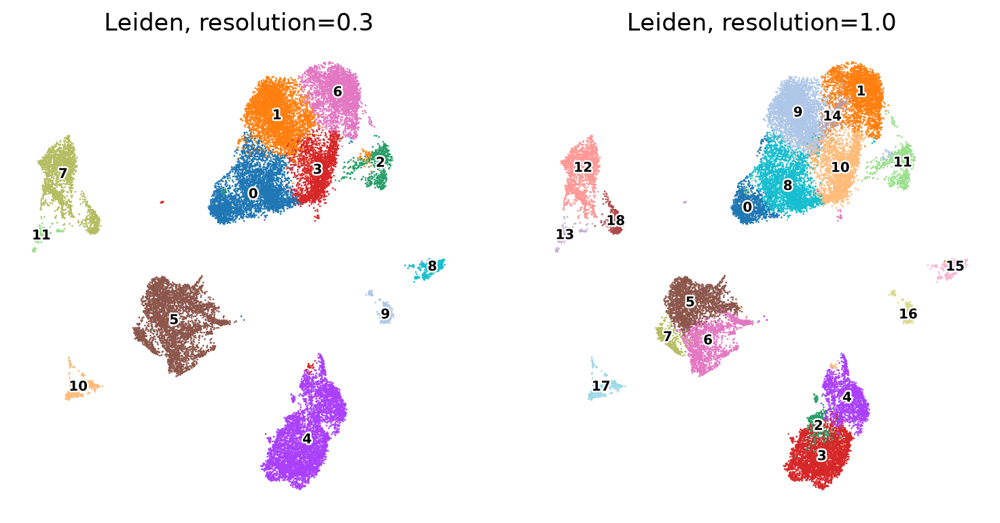

In [23]:
RESOLUTIONS = [0.3, 1.0]
for res in RESOLUTIONS:
    sc.tl.leiden(adata, resolution=res, key_added=f"leiden_{res}", flavor="igraph",
                 n_iterations=2, directed=False, random_state=SEED)
    print(f"resolution={res}: {adata.obs[f'leiden_{res}'].nunique()} кластеров")

sc.pl.umap(adata, color=[f"leiden_{r}" for r in RESOLUTIONS], legend_loc="on data",
           legend_fontsize=8, legend_fontoutline=2, ncols=2, wspace=0.05,
           title=[f"Leiden, resolution={r}" for r in RESOLUTIONS])

leiden_0.3: 12 кластеров; размер min=235, медиана=2067, max=5023
leiden_1.0: 19 кластеров; размер min=252, медиана=1214, max=3439
ARI между разбиениями: 0.718


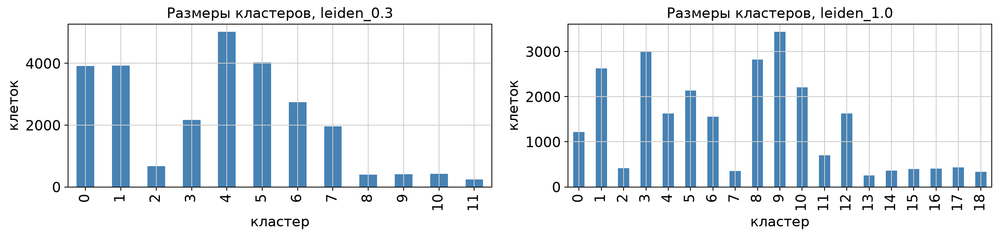

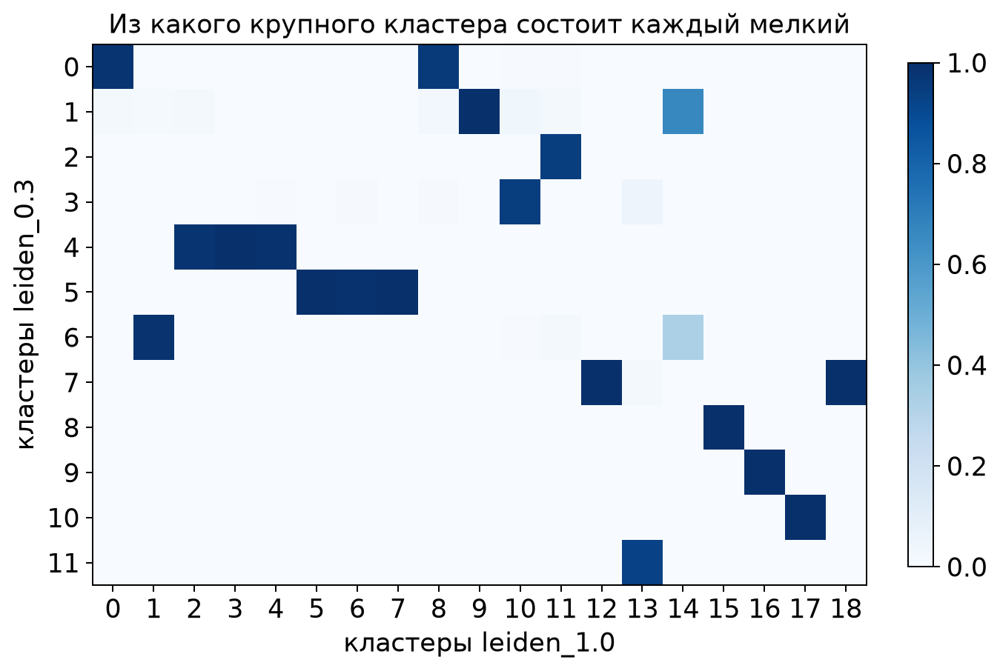

Как кластеры res=0.3 распались при res=1.0:
    0 [ 3912 кл.] -> РАЗДЕЛИЛСЯ: 0 (1190), 8 (2703)
    1 [ 3925 кл.] -> РАЗДЕЛИЛСЯ: 9 (3433), 14 (237)
    2 [  666 кл.] -> сохранился: 11 (665)
    3 [ 2169 кл.] -> сохранился: 10 (2095)
    4 [ 5023 кл.] -> РАЗДЕЛИЛСЯ: 2 (408), 3 (2994), 4 (1619)
    5 [ 4031 кл.] -> РАЗДЕЛИЛСЯ: 5 (2133), 6 (1542), 7 (349)
    6 [ 2740 кл.] -> сохранился: 1 (2590)
    7 [ 1965 кл.] -> РАЗДЕЛИЛСЯ: 12 (1625), 18 (334)
    8 [  400 кл.] -> сохранился: 15 (400)
    9 [  406 кл.] -> сохранился: 16 (405)
   10 [  429 кл.] -> сохранился: 17 (429)
   11 [  235 кл.] -> сохранился: 13 (235)
Средняя «чистота» вложения (доля мелкого кластера из одного крупного): 0.97


In [24]:
from sklearn.metrics import adjusted_rand_score

k_lo, k_hi = "leiden_0.3", "leiden_1.0"
for k in (k_lo, k_hi):
    sz = adata.obs[k].value_counts()
    print(f"{k}: {len(sz)} кластеров; размер min={sz.min()}, медиана={int(sz.median())}, max={sz.max()}")
print("ARI между разбиениями:", round(adjusted_rand_score(adata.obs[k_lo], adata.obs[k_hi]), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, k in zip(axes, (k_lo, k_hi)):
    adata.obs[k].value_counts().sort_index().plot(kind="bar", ax=ax, color="steelblue")
    ax.set(title=f"Размеры кластеров, {k}", xlabel="кластер", ylabel="клеток")
plt.tight_layout()
plt.show()

ct = pd.crosstab(adata.obs[k_lo], adata.obs[k_hi])
frac = ct / ct.sum(axis=0)              # какая доля мелкого кластера пришла из каждого крупного
fig, ax = plt.subplots(figsize=(0.32 * ct.shape[1] + 2, 0.32 * ct.shape[0] + 1.5))
im = ax.imshow(frac.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(ct.shape[1]))
ax.set_xticklabels(ct.columns)
ax.set_yticks(range(ct.shape[0]))
ax.set_yticklabels(ct.index)
ax.set(xlabel=f"кластеры {k_hi}", ylabel=f"кластеры {k_lo}",
       title="Из какого крупного кластера состоит каждый мелкий")
ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.03)
plt.show()

parent = frac.idxmax(axis=0)
print("Как кластеры res=0.3 распались при res=1.0:")
for coarse in ct.index:
    kids = list(parent.index[parent == coarse])
    tag = "РАЗДЕЛИЛСЯ" if len(kids) > 1 else "сохранился"
    sizes = ", ".join(f"{k} ({ct.loc[coarse, k]})" for k in kids)
    print(f"  {coarse:>3} [{ct.loc[coarse].sum():5d} кл.] -> {tag}: {sizes}")
print(f"Средняя «чистота» вложения (доля мелкого кластера из одного крупного): {frac.max(axis=0).mean():.2f}")

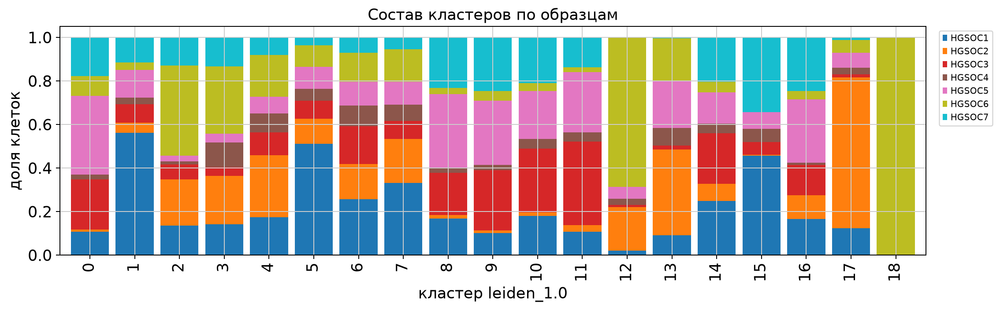

Кластеры, где > 80 % клеток из одного образца (кандидаты в опухолевые или батч-специфичные):
18 (HGSOC6, 100%)


In [25]:
comp = pd.crosstab(adata.obs[k_hi], adata.obs["sample"], normalize="index")
ax = comp.plot(kind="bar", stacked=True, figsize=(14, 3.8), width=0.85, colormap="tab10")
ax.set(ylabel="доля клеток", xlabel=f"кластер {k_hi}", title="Состав кластеров по образцам")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.show()

dominant = comp.max(axis=1)
patient_specific = dominant[dominant > 0.8]
print("Кластеры, где > 80 % клеток из одного образца (кандидаты в опухолевые или батч-специфичные):")
print(", ".join(f"{c} ({comp.loc[c].idxmax()}, {v:.0%})" for c, v in patient_specific.items()) or "нет")

**Ответы на вопросы.**

- **Как `resolution` влияет на число кластеров?** С ростом γ число кластеров растёт, а их средний размер падает: модулярность с бо́льшим γ сильнее штрафует крупные сообщества, и оптимальным становится более дробное разбиение. Конкретные числа для двух разрешений напечатаны выше.
- **Какие кластеры разделились?** Это видно по тепловой карте вложения и по списку «РАЗДЕЛИЛСЯ». Обычно дробятся самые крупные и неоднородные компартменты: T/NK-клетки (CD4, CD8, Treg, NK), миелоидные клетки (моноциты, макрофаги разных состояний), фибробласты, а опухолевый эпителий распадается **по пациенткам** (см. состав кластеров по образцам). Мелкие однородные популяции (тучные клетки, pDC, эндотелий) обычно сохраняются целиком. Высокая «чистота» вложения означает, что разбиения почти иерархичны: мелкие кластеры — подразбиения крупных, а не новая независимая структура.
- **Обязательно ли каждый кластер — отдельный тип клеток? Нет.** Кластер — это плотная область графа, и причины такой плотности бывают разные:
  - функциональное **состояние** того же типа (пролиферация, интерфероновый ответ, стресс диссоциации);
  - **пациентка** (опухолевые клетки с разными CNV, остаточный батч-эффект);
  - **технический артефакт** (низкое качество, дублеты, примесь фоновой РНК);
  - участок **непрерывного** перехода (дифференцировка, активация).

  Поэтому при аннотации разным кластерам можно присвоить одну метку, а один кластер-смесь пометить `Unknown`.

---
## Задание 4. Ручная аннотация

Для аннотации берём разрешение **1.0**. Оно мельче, поэтому редкие популяции (pDC, тучные клетки, плазматические клетки) выделяются в отдельные кластеры. Кластеры одного типа потом объединяются одной меткой.

### 4.1. Маркеры кластеров (Wilcoxon, кластер против всех остальных)

In [26]:
CLUSTER_KEY = "leiden_1.0"
sc.tl.rank_genes_groups(adata, groupby=CLUSTER_KEY, method="wilcoxon", reference="rest",
                        use_raw=False, layer=None, tie_correct=True, pts=True,
                        corr_method="benjamini-hochberg", key_added="wilcoxon")

ranking genes
    finished (0:01:28)


In [27]:
NOISE_GENES = r"^(MT-|RP[SL]\d|HB[AB]\d?$|MALAT1$|NEAT1$)"

markers = sc.get.rank_genes_groups_df(adata, group=None, key="wilcoxon")
markers.to_csv(RESULTS_DIR / "markers_all_clusters.csv", index=False)

markers_f = markers[
    (markers["pvals_adj"] < 0.05)
    & (markers["logfoldchanges"] > 1)
    & (markers["pct_nz_group"] >= 0.25)
    & ((markers["pct_nz_group"] - markers["pct_nz_reference"]) >= 0.15)
    & ~markers["names"].str.match(NOISE_GENES)
].sort_values(["group", "scores"], ascending=[True, False])
markers_f.to_csv(RESULTS_DIR / "markers_filtered.csv", index=False)

clusters = list(adata.obs[CLUSTER_KEY].cat.categories)
top_de = (markers_f.groupby("group", observed=True).head(6)
          .groupby("group", observed=True)
          .apply(lambda d: ", ".join(f"{g} ({p:.0%}/{q:.0%})" for g, p, q in
                                     zip(d["names"], d["pct_nz_group"], d["pct_nz_reference"]))))
top_de = top_de.reindex(clusters).fillna("— (нет генов, прошедших фильтр)")
print("Топ маркеры кластеров: ген (доля экспрессирующих в кластере / в остальных клетках)")
with pd.option_context("display.max_colwidth", 200):
    display(top_de.rename("top DE genes").to_frame())

Топ маркеры кластеров: ген (доля экспрессирующих в кластере / в остальных клетках)


,top DE genes
group,
0,"FOXP3 (75%/3%), IL2RA (54%/4%), CTLA4 (85%/12%), TNFRSF4 (80%/11%), LAIR2 (61%/6%), ICOS (68%/11%)"
1,"TRDC (89%/5%), KRT81 (58%/3%), XCL1 (69%/6%), XCL2 (80%/10%), GNLY (87%/19%), KLRD1 (79%/12%)"
2,"DEPDC1 (71%/3%), NEK2 (68%/3%), PBK (76%/4%), KIF4A (71%/4%), FAM83D (62%/3%), NMU (70%/4%)"
3,"CDH1 (83%/4%), PRSS8 (83%/4%), CXADR (84%/5%), DSP (95%/8%), RAB25 (81%/4%), SCNN1A (81%/5%)"
4,"WFDC2 (86%/47%), KRT18 (76%/32%), KRT8 (68%/28%), CD24 (58%/24%), S100A13 (63%/30%), KRT19 (58%/23%)"
5,"C1QC (87%/6%), MS4A7 (86%/6%), MSR1 (82%/5%), C1QA (93%/10%), TREM2 (78%/5%), FCGR2A (88%/8%)"
6,"FCN1 (43%/1%), LYZ (83%/13%), SPI1 (80%/11%), AIF1 (85%/14%), NCF2 (61%/6%), EREG (36%/2%)"
7,"GTSE1 (85%/5%), AURKB (81%/5%), NCAPG (79%/5%), CKAP2L (68%/4%), HMMR (79%/5%), CEP55 (83%/6%)"
8,"IL7R (68%/13%), CD40LG (37%/2%), LTB (89%/35%), CD2 (92%/41%), CD3D (87%/31%), SPOCK2 (68%/24%)"


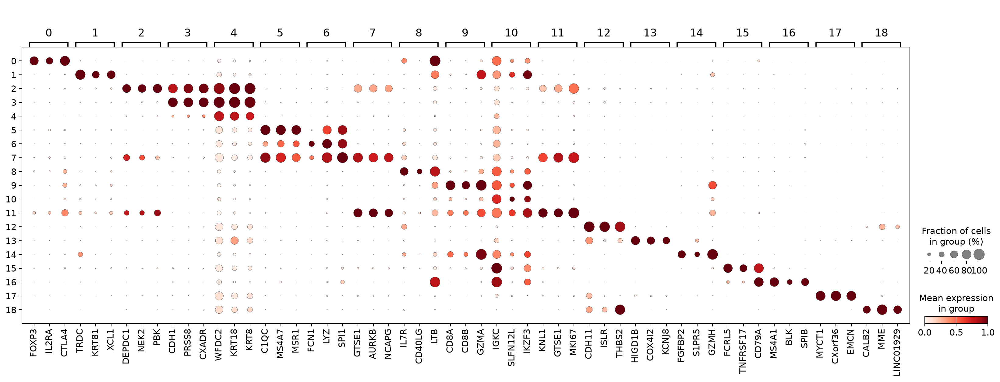

In [28]:
top3 = markers_f.groupby("group", observed=True).head(3)
dot_genes = {str(g): list(d["names"]) for g, d in top3.groupby("group", observed=True) if len(d)}
dot_genes = {c: dot_genes[c] for c in clusters if c in dot_genes}
sc.pl.dotplot(adata, var_names=dot_genes, groupby=CLUSTER_KEY, standard_scale="var",
              use_raw=False, dendrogram=False)

### 4.2. Известные маркеры клеточных типов TME HGSOC

Источники: PanglaoDB (Franzén et al., *Database* 2019), CellMarker 2.0 (Hu et al., *NAR* 2023) и аннотации в работах по HGSOC (Izar et al., *Nat Med* 2020; Olbrecht et al., *Genome Med* 2021; Xu et al., *Clin Cancer Res* 2022).

| Тип | Маркеры | Комментарий |
|---|---|---|
| Эпителий / опухоль HGSOC | `EPCAM`, `KRT8`, `KRT18`, `KRT19`, `PAX8`, `MUC16`, `CLDN4` | `PAX8` — маркер мюллерова (трубного) происхождения HGSOC. Что клетки именно злокачественные, строго доказывается только по CNV (inferCNV) |
| Фибробласты / CAF | `DCN`, `LUM`, `COL1A1`, `COL1A2`, `COL3A1`, `PDGFRA` | mCAF: `ACTA2`, `COL10A1`, `MMP11`, `POSTN` |
| Перициты / ГМК | `RGS5`, `ACTA2`, `MYH11`, `TAGLN`, `PDGFRB`, `MCAM` | `ACTA2` есть и у миофибробластов |
| Эндотелий | `PECAM1`, `VWF`, `CDH5`, `CLDN5`, `PLVAP`, `EMCN` | |
| CD4⁺ T | `CD3D`, `CD3E`, `CD4`, `IL7R` | `CD4` на уровне мРНК есть и у макрофагов |
| Treg | `FOXP3`, `IL2RA`, `CTLA4`, `IKZF2` | |
| CD8⁺ T | `CD3D`, `CD8A`, `CD8B`, `GZMK` | |
| NK | `KLRF1`, `NCAM1`, `KLRD1`, `GNLY`, `PRF1` | `GNLY`/`PRF1` есть и у CD8 эффекторов |
| B-клетки | `MS4A1`, `CD19`, `BANK1`, `CD79B` | |
| Плазматические клетки | `JCHAIN`, `MZB1`, `IGHG1`, `IGKC`, `SDC1` | |
| Макрофаги | `CD68`, `CD163`, `C1QA`, `C1QB`, `C1QC`, `MRC1` | |
| Моноциты | `CD14`, `FCN1`, `S100A8`, `S100A9`, `VCAN`, `LYZ` | |
| cDC | `CD1C`, `FCER1A`, `CLEC10A`, `CLEC9A`, `LAMP3` | `CLEC9A` — cDC1, `LAMP3` — зрелые DC |
| pDC | `LILRA4`, `CLEC4C`, `IL3RA`, `PLD4` | |
| Тучные клетки | `TPSAB1`, `TPSB2`, `CPA3`, `KIT`, `MS4A2` | |
| Пролиферирующие (состояние) | `MKI67`, `TOP2A`, `CENPF`, `NUSAP1` | состояние любого типа, а не отдельный тип |
| Эритроциты (примесь) | `HBB`, `HBA1`, `HBA2` | |

Нет в данных (отфильтрованы или отсутствуют): {'Mast cell': ['MS4A2']}


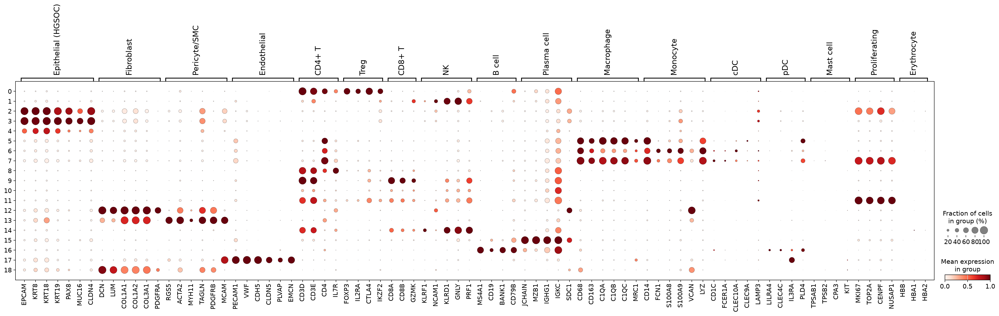

In [29]:
CANONICAL = {
    "Epithelial (HGSOC)": ["EPCAM", "KRT8", "KRT18", "KRT19", "PAX8", "MUC16", "CLDN4"],
    "Fibroblast":         ["DCN", "LUM", "COL1A1", "COL1A2", "COL3A1", "PDGFRA"],
    "Pericyte/SMC":       ["RGS5", "ACTA2", "MYH11", "TAGLN", "PDGFRB", "MCAM"],
    "Endothelial":        ["PECAM1", "VWF", "CDH5", "CLDN5", "PLVAP", "EMCN"],
    "CD4+ T":             ["CD3D", "CD3E", "CD4", "IL7R"],
    "Treg":               ["FOXP3", "IL2RA", "CTLA4", "IKZF2"],
    "CD8+ T":             ["CD3D", "CD8A", "CD8B", "GZMK"],
    "NK":                 ["KLRF1", "NCAM1", "KLRD1", "GNLY", "PRF1"],
    "B cell":             ["MS4A1", "CD19", "BANK1", "CD79B"],
    "Plasma cell":        ["JCHAIN", "MZB1", "IGHG1", "IGKC", "SDC1"],
    "Macrophage":         ["CD68", "CD163", "C1QA", "C1QB", "C1QC", "MRC1"],
    "Monocyte":           ["CD14", "FCN1", "S100A8", "S100A9", "VCAN", "LYZ"],
    "cDC":                ["CD1C", "FCER1A", "CLEC10A", "CLEC9A", "LAMP3"],
    "pDC":                ["LILRA4", "CLEC4C", "IL3RA", "PLD4"],
    "Mast cell":          ["TPSAB1", "TPSB2", "CPA3", "KIT", "MS4A2"],
    "Proliferating":      ["MKI67", "TOP2A", "CENPF", "NUSAP1"],
    "Erythrocyte":        ["HBB", "HBA1", "HBA2"],
}
COMPARTMENT = {
    "Epithelial (HGSOC)": "Epithelial",
    "Fibroblast": "Stromal", "Pericyte/SMC": "Stromal", "Endothelial": "Stromal",
    "CD4+ T": "T/NK", "Treg": "T/NK", "CD8+ T": "T/NK", "NK": "T/NK",
    "B cell": "B/Plasma", "Plasma cell": "B/Plasma",
    "Macrophage": "Myeloid/DC", "Monocyte": "Myeloid/DC", "cDC": "Myeloid/DC", "pDC": "Myeloid/DC",
    "Mast cell": "Mast", "Erythrocyte": "Other", "Unknown": "Other",
}
STATE_SETS = ("Proliferating",)

canon_present = {t: [g for g in gs if g in adata.var_names] for t, gs in CANONICAL.items()}
missing = {t: sorted(set(gs) - set(canon_present[t])) for t, gs in CANONICAL.items() if set(gs) - set(canon_present[t])}
if missing:
    print("Нет в данных (отфильтрованы или отсутствуют):", missing)
canon_present = {t: gs for t, gs in canon_present.items() if gs}

# один ген в dotplot показываем один раз (CD3D входит в два набора)
seen, canon_dot = set(), {}
for t, gs in canon_present.items():
    uniq = [g for g in gs if g not in seen]
    seen.update(uniq)
    if uniq:
        canon_dot[t] = uniq
sc.pl.dotplot(adata, var_names=canon_dot, groupby=CLUSTER_KEY, standard_scale="var",
              use_raw=False)

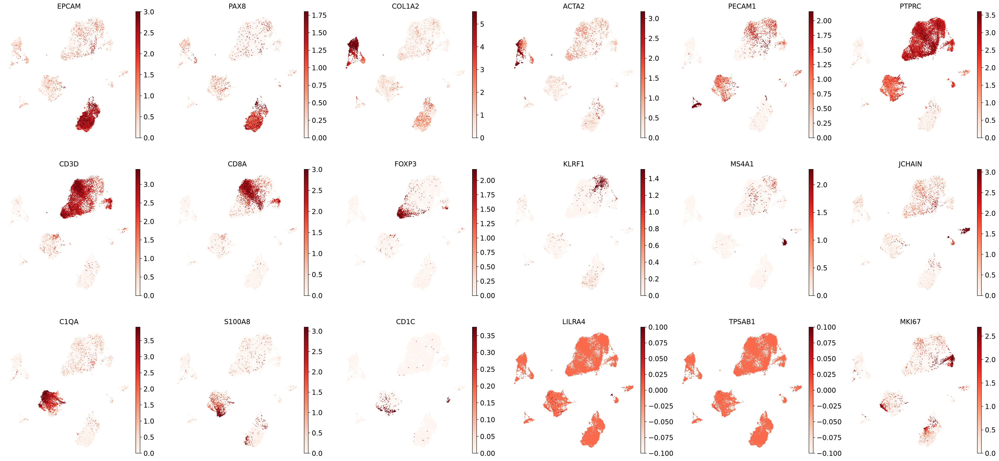

In [30]:
umap_markers = [g for g in ["EPCAM", "PAX8", "COL1A2", "ACTA2", "PECAM1", "PTPRC",
                            "CD3D", "CD8A", "FOXP3", "KLRF1", "MS4A1", "JCHAIN",
                            "C1QA", "S100A8", "CD1C", "LILRA4", "TPSAB1", "MKI67"]
                if g in adata.var_names]
sc.pl.umap(adata, color=umap_markers, ncols=6, cmap="Reds", vmax="p99", size=6, frameon=False)

### 4.3. Присвоение типов кластерам

Для каждого кластера считаем среднюю экспрессию каждого канонического маркера, переводим её в z-score между кластерами и усредняем внутри набора маркеров. Получается матрица «кластер × тип». Кластеру присваивается тип с наибольшим z-score, если выполнены условия:
- если лучший z-score меньше `MIN_Z`, ставим `Unknown`: ни один набор не выражен заметно сильнее, чем в остальных кластерах;
- если два лучших кандидата из **разных компартментов** (например, T и эпителий) близки по z-score, ставим `Unknown`: это кандидат в смесь или дублеты;
- если лучший набор — «Proliferating», это состояние, а не тип. Тип берём по следующему по силе набору и добавляем пометку `(cycling)`.

Это **черновик**. Ниже он проверяется по dotplot, по топ-DE генам и по UMAP с маркерами. Решения, принятые вручную, записываются в `MANUAL_OVERRIDES`.

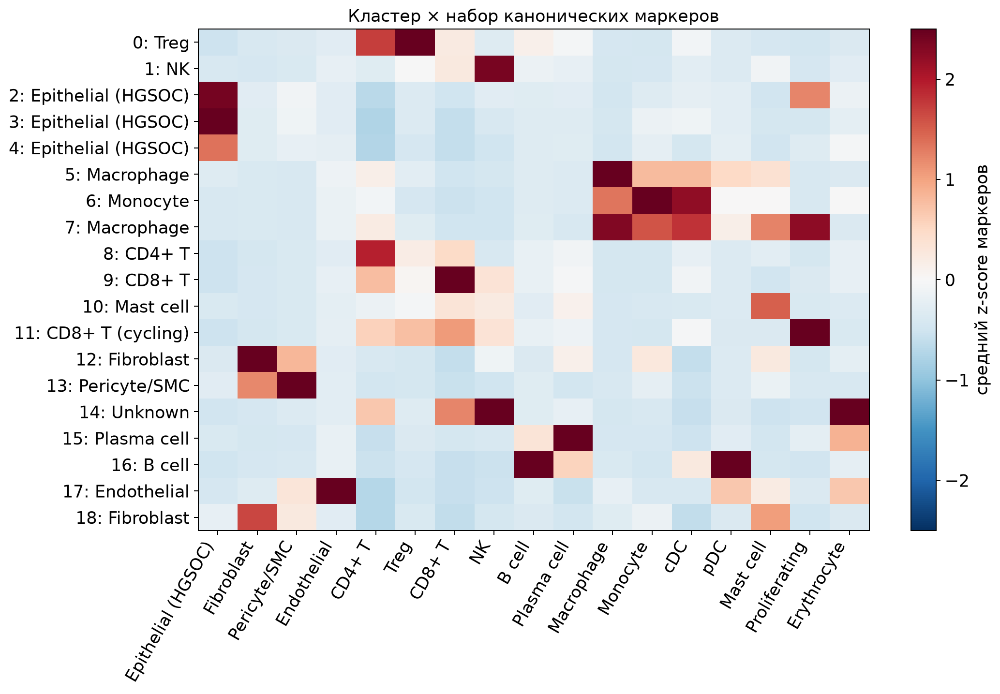

,draft,best,z_best,second,z_second
cluster,,,,,
0,Treg,Treg,3.97,CD4+ T,1.73
1,NK,NK,2.37,CD8+ T,0.25
2,Epithelial (HGSOC),Epithelial (HGSOC),2.40,Proliferating,1.22
3,Epithelial (HGSOC),Epithelial (HGSOC),2.84,Pericyte/SMC,-0.10
4,Epithelial (HGSOC),Epithelial (HGSOC),1.35,Erythrocyte,-0.05
5,Macrophage,Macrophage,2.85,Monocyte,0.79
6,Monocyte,Monocyte,2.72,cDC,2.21
7,Macrophage,Macrophage,2.32,Proliferating,2.24
8,CD4+ T,CD4+ T,1.95,CD8+ T,0.47


In [31]:
def marker_set_zscores(adata, groupby, marker_sets):
    genes = sorted({g for gs in marker_sets.values() for g in gs})
    df = sc.get.obs_df(adata, keys=genes)
    grp = adata.obs[groupby].values
    means = df.groupby(grp, observed=True).mean()
    pct = (df > 0).groupby(grp, observed=True).mean()
    z = (means - means.mean()) / means.std(ddof=0).replace(0, np.nan)
    scores = pd.DataFrame({t: z[gs].mean(axis=1) for t, gs in marker_sets.items()})
    return scores, pct


def assign_labels(scores, compartment, min_z=0.5, min_margin=0.3, state_sets=STATE_SETS):
    rows = []
    for cl, r in scores.iterrows():
        r = r.dropna().sort_values(ascending=False)
        best, second = r.index[0], r.index[1]
        z1, z2 = r.iloc[0], r.iloc[1]
        if best in state_sets:
            base = r.drop([s for s in state_sets if s in r.index]).index[0]
            label = f"{base} (cycling)" if r[base] >= min_z else "Unknown (cycling)"
        elif z1 < min_z:
            label = "Unknown"
        elif (z1 - z2) < min_margin and second not in state_sets \
                and compartment.get(best) != compartment.get(second):
            label = "Unknown"
        else:
            label = best
        rows.append({"cluster": cl, "draft": label, "best": best, "z_best": z1,
                     "second": second, "z_second": z2})
    return pd.DataFrame(rows).set_index("cluster")


def base_type(label):
    return re.sub(r"\s*\(cycling\)$", "", str(label))


type_scores, type_pct = marker_set_zscores(adata, CLUSTER_KEY, canon_present)
draft = assign_labels(type_scores, COMPARTMENT, min_z=0.5, min_margin=0.3)

fig, ax = plt.subplots(figsize=(0.55 * type_scores.shape[1] + 3, 0.32 * type_scores.shape[0] + 1.5))
im = ax.imshow(type_scores.values, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
ax.set_xticks(range(type_scores.shape[1]))
ax.set_xticklabels(type_scores.columns, rotation=60, ha="right")
ax.set_yticks(range(type_scores.shape[0]))
ax.set_yticklabels([f"{c}: {draft.loc[c, 'draft']}" for c in type_scores.index])
plt.colorbar(im, ax=ax, label="средний z-score маркеров")
ax.grid(False)
ax.set_title("Кластер × набор канонических маркеров")
plt.show()
display(draft.round(2))

In [57]:
# единственный неизвестный кластер - это очень нишевые ФГФБП2+ цитотоксические НК-подобные Т-клетки.
# там в общем видны всякие гранзимы + смесь маркеров Т и НК. Дальше гугл в помощь
MANUAL_OVERRIDES = {'14': 'FGFBP2⁺ cytotoxic T cells (NK-like).'}

cluster_labels = {**draft["draft"].to_dict(), **MANUAL_OVERRIDES}
adata.obs["manual_cell_type"] = (adata.obs[CLUSTER_KEY].astype(str).map(cluster_labels)
                                 .fillna("Unknown").astype("category"))
adata.obs["compartment"] = (adata.obs["manual_cell_type"].astype(str).map(base_type)
                            .map(COMPARTMENT).fillna("Other").astype("category"))
display(adata.obs["manual_cell_type"].value_counts().rename("клеток").to_frame())

,клеток
manual_cell_type,
Epithelial (HGSOC),5042
CD8+ T,3439
CD4+ T,2823
NK,2628
Macrophage,2485
Mast cell,2208
Fibroblast,1959
Monocyte,1557
Treg,1214


In [58]:
def df_to_markdown(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(str(r[c]).replace("|", "/") for c in cols) + " |")
    return "\n".join(lines)


samp_frac = pd.crosstab(adata.obs[CLUSTER_KEY], adata.obs["sample"], normalize="index")
dbl_mean = adata.obs.groupby(CLUSTER_KEY, observed=True)["doublet_score"].mean()
rows = []
for c in clusters:
    lab = cluster_labels[c]
    bt = base_type(lab)
    ref = bt if bt in canon_present else draft.loc[c, "best"]
    genes = sorted(canon_present.get(ref, []), key=lambda g: -type_pct.loc[c, g])[:4]
    rows.append({
        "Кластер": c,
        "Клеток": int((adata.obs[CLUSTER_KEY] == c).sum()),
        "Предполагаемый тип": lab,
        "Маркерные гены": ", ".join(f"{g} ({type_pct.loc[c, g]:.0%})" for g in genes),
        "Топ DE-гены": top_de.loc[c].split(", ")[:4] and ", ".join(top_de.loc[c].split(", ")[:4]),
        "Обоснование": (f"z={draft.loc[c, 'z_best']:.2f} для «{draft.loc[c, 'best']}»; "
                        f"2-й кандидат «{draft.loc[c, 'second']}» (z={draft.loc[c, 'z_second']:.2f}); "
                        f"макс. доля одного образца {samp_frac.loc[c].max():.0%}; "
                        f"doublet score {dbl_mean.loc[c]:.2f}"
                        + ("; правка вручную" if c in MANUAL_OVERRIDES else "")),
    })
annot_table = pd.DataFrame(rows)
annot_table.to_csv(RESULTS_DIR / "manual_annotation_table.csv", index=False)
display(Markdown(df_to_markdown(annot_table)))

| Кластер | Клеток | Предполагаемый тип | Маркерные гены | Топ DE-гены | Обоснование |
|---|---|---|---|---|---|
| 0 | 1214 | Treg | CTLA4 (85%), FOXP3 (75%), IKZF2 (59%), IL2RA (54%) | FOXP3 (75%/3%), IL2RA (54%/4%), CTLA4 (85%/12%), TNFRSF4 (80%/11%) | z=3.97 для «Treg»; 2-й кандидат «CD4+ T» (z=1.73); макс. доля одного образца 36%; doublet score 0.04 |
| 1 | 2628 | NK | GNLY (87%), KLRD1 (79%), PRF1 (71%), NCAM1 (36%) | TRDC (89%/5%), KRT81 (58%/3%), XCL1 (69%/6%), XCL2 (80%/10%) | z=2.37 для «NK»; 2-й кандидат «CD8+ T» (z=0.25); макс. доля одного образца 56%; doublet score 0.05 |
| 2 | 416 | Epithelial (HGSOC) | KRT8 (99%), KRT18 (99%), CLDN4 (98%), EPCAM (97%) | DEPDC1 (71%/3%), NEK2 (68%/3%), PBK (76%/4%), KIF4A (71%/4%) | z=2.40 для «Epithelial (HGSOC)»; 2-й кандидат «Proliferating» (z=1.22); макс. доля одного образца 41%; doublet score 0.08 |
| 3 | 2994 | Epithelial (HGSOC) | KRT18 (100%), KRT8 (99%), CLDN4 (99%), EPCAM (98%) | CDH1 (83%/4%), PRSS8 (83%/4%), CXADR (84%/5%), DSP (95%/8%) | z=2.84 для «Epithelial (HGSOC)»; 2-й кандидат «Pericyte/SMC» (z=-0.10); макс. доля одного образца 31%; doublet score 0.06 |
| 4 | 1632 | Epithelial (HGSOC) | KRT18 (76%), KRT8 (68%), KRT19 (58%), EPCAM (53%) | WFDC2 (86%/47%), KRT18 (76%/32%), KRT8 (68%/28%), CD24 (58%/24%) | z=1.35 для «Epithelial (HGSOC)»; 2-й кандидат «Erythrocyte» (z=-0.05); макс. доля одного образца 28%; doublet score 0.05 |
| 5 | 2136 | Macrophage | C1QA (93%), C1QB (88%), C1QC (87%), CD68 (83%) | C1QC (87%/6%), MS4A7 (86%/6%), MSR1 (82%/5%), C1QA (93%/10%) | z=2.85 для «Macrophage»; 2-й кандидат «Monocyte» (z=0.79); макс. доля одного образца 51%; doublet score 0.06 |
| 6 | 1557 | Monocyte | LYZ (83%), CD14 (70%), S100A9 (67%), S100A8 (51%) | FCN1 (43%/1%), LYZ (83%/13%), SPI1 (80%/11%), AIF1 (85%/14%) | z=2.72 для «Monocyte»; 2-й кандидат «cDC» (z=2.21); макс. доля одного образца 26%; doublet score 0.06 |
| 7 | 349 | Macrophage | CD68 (95%), C1QA (92%), C1QB (90%), C1QC (90%) | GTSE1 (85%/5%), AURKB (81%/5%), NCAPG (79%/5%), CKAP2L (68%/4%) | z=2.32 для «Macrophage»; 2-й кандидат «Proliferating» (z=2.24); макс. доля одного образца 33%; doublet score 0.08 |
| 8 | 2823 | CD4+ T | CD3D (87%), CD3E (77%), IL7R (68%), CD4 (42%) | IL7R (68%/13%), CD40LG (37%/2%), LTB (89%/35%), CD2 (92%/41%) | z=1.95 для «CD4+ T»; 2-й кандидат «CD8+ T» (z=0.47); макс. доля одного образца 34%; doublet score 0.06 |
| 9 | 3439 | CD8+ T | CD3D (95%), CD8A (82%), CD8B (67%), GZMK (43%) | CD8A (82%/8%), CD8B (67%/6%), GZMA (94%/25%), NKG7 (96%/28%) | z=3.04 для «CD8+ T»; 2-й кандидат «CD4+ T» (z=0.77); макс. доля одного образца 30%; doublet score 0.06 |
| 10 | 2208 | Mast cell | KIT (0%), CPA3 (0%), TPSAB1 (0%), TPSB2 (0%) | IGKC (81%/62%), SLFN12L (36%/18%), IKZF3 (49%/34%), CCL5 (76%/52%) | z=1.49 для «Mast cell»; 2-й кандидат «CD8+ T» (z=0.33); макс. доля одного образца 29%; doublet score 0.04 |
| 11 | 703 | CD8+ T (cycling) | CD3D (76%), CD8A (45%), CD8B (38%), GZMK (25%) | KNL1 (78%/5%), GTSE1 (75%/4%), MKI67 (97%/9%), AURKB (73%/4%) | z=3.10 для «Proliferating»; 2-й кандидат «CD8+ T» (z=1.06); макс. доля одного образца 38%; doublet score 0.07 |
| 12 | 1625 | Fibroblast | COL1A1 (100%), COL1A2 (100%), COL3A1 (100%), DCN (99%) | CDH11 (95%/3%), ISLR (92%/3%), THBS2 (91%/3%), GLT8D2 (77%/1%) | z=3.28 для «Fibroblast»; 2-й кандидат «Pericyte/SMC» (z=0.83); макс. доля одного образца 68%; doublet score 0.04 |
| 13 | 252 | Pericyte/SMC | ACTA2 (91%), PDGFRB (89%), TAGLN (88%), MCAM (87%) | HIGD1B (74%/0%), COX4I2 (64%/1%), KCNJ8 (57%/0%), ABCC9 (56%/0%) | z=3.66 для «Pericyte/SMC»; 2-й кандидат «Fibroblast» (z=1.21); макс. доля одного образца 39%; doublet score 0.06 |
| 14 | 357 | FGFBP2⁺ cytotoxic T cells (NK-like). | HBA1 (4%), HBA2 (1%), HBB (0%) | FGFBP2 (64%/1%), S1PR5 (37%/1%), GZMH (94%/18%), CX3CR1 (49%/6%) | z=2.62 для «Erythrocyte»; 2-й кандидат «NK» (z=2.55); макс. доля одного образца 25%; doublet score 0.04; правка вручную |
| 15 | 400 | Plasma cell | MZB1 (98%), IGKC (95%), IGHG1 (95%), JCHAIN (95%) | FCRL5 (78%/1%), TNFRSF17 (60%/0%), CD79A (84%/4%), POU2AF1 (74%/3%) | z=3.38 для «Plasma cell»; 2-й кандидат «Erythrocyte» (z=0.88); макс. доля одного образца 46%; doublet score 0.06 |
| 16 | 405 | B cell | MS4A1 (79%), BANK1 (69%), CD79B (69%), CD19 (36%) | MS4A1 (79%/2%), BLK (38%/0%), SPIB (61%/1%), PAX5 (29%/0%) | z=4.06 для «B cell»; 2-й кандидат «pDC» (z=3.23); макс. доля одного образца 29%; doublet score 0.04 |
| 17 | 429 | Endothelial | VWF (99%), CDH5 (96%), PECAM1 (95%), EMCN (84%) | MYCT1 (85%/0%), CXorf36 (89%/0%), EMCN (84%/0%), PCDH17 (88%/0%) | z=4.21 для «Endothelial»; 2-й кандидат «Erythrocyte» (z=0.67); макс. доля одного образца 69%; doublet score 0.05 |
| 18 | 334 | Fibroblast | DCN (99%), COL1A2 (93%), COL3A1 (93%), COL1A1 (93%) | CALB2 (61%/1%), MME (91%/4%), LINC01929 (69%/2%), GREM1 (54%/1%) | z=1.68 для «Fibroblast»; 2-й кандидат «Mast cell» (z=1.05); макс. доля одного образца 100%; doublet score 0.03 |

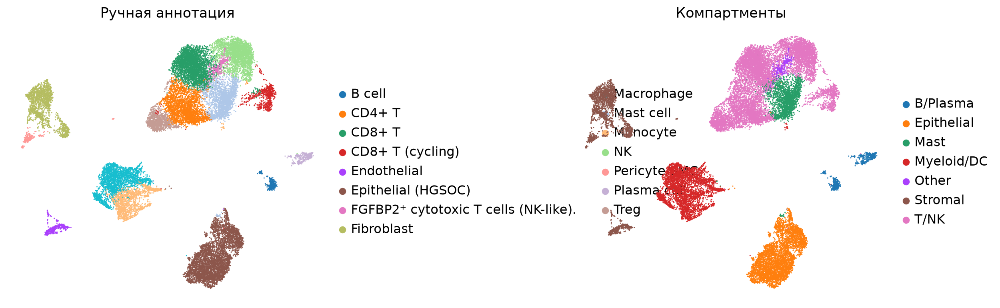

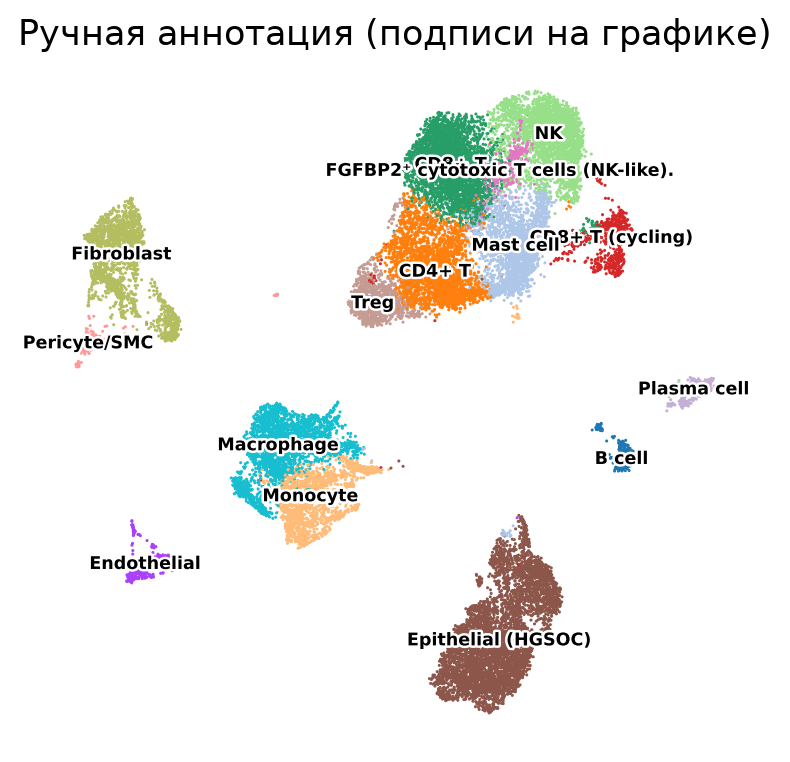

In [60]:
sc.pl.umap(adata, color=["manual_cell_type", "compartment"], ncols=2, wspace=0.6, size=6,
           title=["Ручная аннотация", "Компартменты"])
sc.pl.umap(adata, color="manual_cell_type", legend_loc="on data", legend_fontsize=7,
           legend_fontoutline=2, size=6, title="Ручная аннотация (подписи на графике)")

**Как читать таблицу.** В столбце «Маркерные гены» указана доля клеток кластера, экспрессирующих канонический маркер присвоенного типа, а в «Топ DE-генах» — доля экспрессирующих в кластере и во всех остальных клетках. «Обоснование» объединяет количественные аргументы:
- насколько набор маркеров выражен сильнее, чем в других кластерах;
- был ли близкий альтернативный кандидат;
- специфичен ли кластер для одной пациентки (характерно для опухолевого эпителия);
- нет ли признаков дублетов.

**Что проверить вручную перед сдачей:**
- Кластеры, специфичные для одной пациентки и экспрессирующие `EPCAM`/`PAX8`, — опухолевые клетки этой пациентки. Это ожидаемо: у каждой опухоли свой набор CNV.
- `Unknown` или два близких кандидата из разных компартментов — посмотрите топ-DE гены. Если там маркеры двух разных типов и doublet score выше среднего, это дублеты, метку `Unknown` стоит оставить.
- `Pericyte/SMC` против `Fibroblast`: mCAF экспрессируют `ACTA2`, поэтому смотрите `RGS5`/`MCAM` (перициты) против `DCN`/`LUM` (фибробласты).
- Если в данных есть мезотелий (`MSLN`⁺ `UPK3B`⁺ `CALB2`⁺, без `PAX8`), добавьте его вручную через `MANUAL_OVERRIDES`.

---
## Задание 5. Автоматическая аннотация (CellTypist)

**Выбор модели.** В CellTypist нет модели для яичника или HGSOC (полный список моделей: https://www.celltypist.org/models). Поэтому:
1. **`Immune_All_Low.pkl`** (98 типов иммунных клеток из 20 тканей) — основная модель для иммунного микроокружения. Она не знает эпителия и стромы, и это ограничение мы покажем явно: на неиммунных клетках у неё низкая уверенность.
2. **`Human_Endometrium_Atlas.pkl`** (36 типов эндометрия, интегрировано из 7 датасетов) — альтернатива для эпителия и стромы. Эндометрий, как и маточная труба (откуда происходит большинство HGSOC), — производное мюллерова протока, поэтому эпителий и стромальные типы там ближе всего к нашим.

Обе модели запускаем на **всех клетках** с `majority_voting=True`: метка уточняется голосованием внутри мелких кластеров (over-clustering на нашем графе соседей).

In [61]:
import celltypist
from celltypist import models as ct_models
# в итоге я скачал через вгет. тк у них с сайтом что то

def load_celltypist_model(name):
    try:
        return ct_models.Model.load(name)
    except Exception:
        print(f"{name}: локально не найдена, скачиваю...")
        ct_models.download_models(model=name, force_update=False)
        return ct_models.Model.load(name)


def run_celltypist(adata, model_name, prefix, majority_voting=True):
    model = load_celltypist_model(model_name)
    pred = celltypist.annotate(adata.copy(), model=model, majority_voting=majority_voting)
    lab = pred.predicted_labels.reindex(adata.obs_names)
    assert lab["predicted_labels"].notna().all(), "Часть клеток потеряна"
    adata.obs[f"{prefix}_cell"] = pd.Categorical(lab["predicted_labels"].astype(str))
    if majority_voting:
        adata.obs[f"{prefix}_mv"] = pd.Categorical(lab["majority_voting"].astype(str))
    adata.obs[f"{prefix}_conf"] = pred.probability_matrix.max(axis=1).reindex(adata.obs_names).astype(float).values
    print(f"{model_name}: {lab['predicted_labels'].nunique()} меток на уровне клеток")
    return model


ct_immune_model = run_celltypist(adata, "/home/STUDY/FBMF/studfbmf01_12/Immune_All_Low.pkl", "ct_immune")
display(adata.obs["ct_immune_mv"].value_counts().head(25).rename("клеток").to_frame())


🔬 Input data has 25901 cells and 21895 genes
🔗 Matching reference genes in the model
🧬 5629 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 15


running Leiden clustering
    finished (0:00:00)


🗳️ Majority voting the predictions
✅ Majority voting done!


/home/STUDY/FBMF/studfbmf01_12/Immune_All_Low.pkl: 63 меток на уровне клеток


,клеток
ct_immune_mv,
Epithelial cells,4945
Tem/Trm cytotoxic T cells,4707
Macrophages,3757
Regulatory T cells,3027
Fibroblasts,2183
CD16- NK cells,1890
Tem/Effector helper T cells,1225
NK cells,1127
Endothelial cells,563


In [62]:
ct_endo_model = run_celltypist(adata, "/home/STUDY/FBMF/studfbmf01_12/Human_Endometrium_Atlas.pkl", "ct_endo")
display(adata.obs["ct_endo_mv"].value_counts().head(25).rename("клеток").to_frame())

🔬 Input data has 25901 cells and 21895 genes
🔗 Matching reference genes in the model
🧬 3726 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 15


running Leiden clustering
    finished (0:00:00)


🗳️ Majority voting the predictions
✅ Majority voting done!


/home/STUDY/FBMF/studfbmf01_12/Human_Endometrium_Atlas.pkl: 35 меток на уровне клеток


,клеток
ct_endo_mv,
Immune_Lymphoid,14816
Immune_Myeloid,4105
eHormones,3266
eStromal_MMPs,942
SOX9_luminal,765
ePV_2,587
Venous,563
Fibroblast_basalis,504
Glandular_secretory_FGF7,164


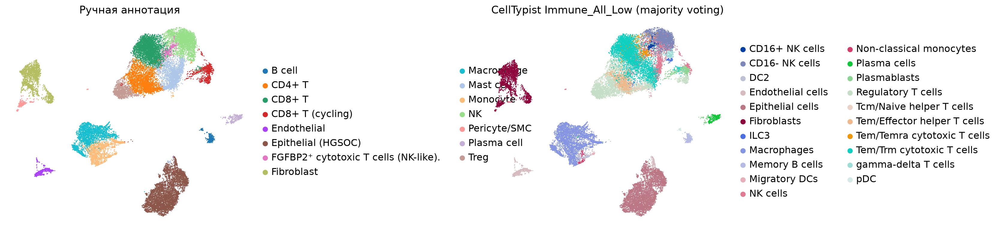

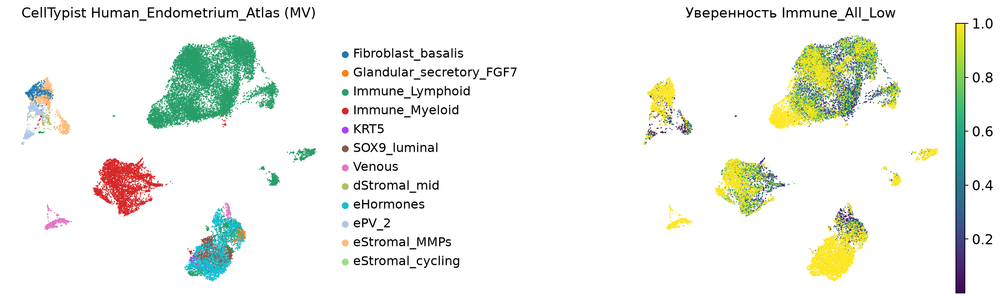

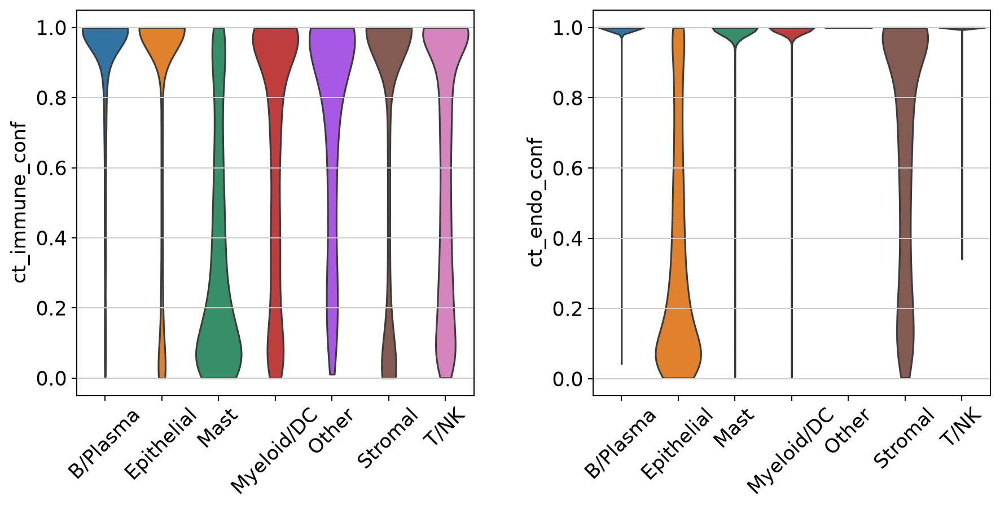

In [63]:
sc.pl.umap(adata, color=["manual_cell_type", "ct_immune_mv"], ncols=2, wspace=0.75, size=6,
           title=["Ручная аннотация", "CellTypist Immune_All_Low (majority voting)"])
sc.pl.umap(adata, color=["ct_endo_mv", "ct_immune_conf"], ncols=2, wspace=0.75, size=6,
           cmap="viridis", title=["CellTypist Human_Endometrium_Atlas (MV)", "Уверенность Immune_All_Low"])
sc.pl.violin(adata, ["ct_immune_conf", "ct_endo_conf"], groupby="compartment",
             stripplot=False, rotation=45)

ct_immune_mv,CD16+ NK cells,CD16- NK cells,DC2,Endothelial cells,Epithelial cells,Fibroblasts,ILC3,Macrophages,Memory B cells,Migratory DCs,NK cells,Non-classical monocytes,Plasma cells,Plasmablasts,Regulatory T cells,Tcm/Naive helper T cells,Tem/Effector helper T cells,Tem/Temra cytotoxic T cells,Tem/Trm cytotoxic T cells,gamma-delta T cells,pDC
manual_cell_type,,,,,,,,,,,,,,,,,,,,,
B cell,0,0,0,0,0,0,0,0,333,0,0,0,0,0,0,0,0,0,0,0,72
CD4+ T,0,2,0,0,0,0,43,0,0,0,31,0,0,0,1069,144,1220,1,313,0,0
CD8+ T,0,12,1,0,0,0,0,0,0,0,92,0,0,0,121,0,3,166,3044,0,0
CD8+ T (cycling),0,0,0,0,0,0,0,0,0,0,108,0,0,352,218,0,0,0,25,0,0
Endothelial,0,0,0,429,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Epithelial (HGSOC),0,0,0,131,4902,3,0,1,0,0,3,0,0,0,1,0,0,0,1,0,0
FGFBP2⁺ cytotoxic T cells (NK-like).,122,1,0,0,0,0,0,0,0,0,3,0,0,0,0,0,0,196,35,0,0
Fibroblast,0,0,0,3,1,1955,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Macrophage,0,0,0,0,1,0,0,2480,0,0,0,0,4,0,0,0,0,0,0,0,0


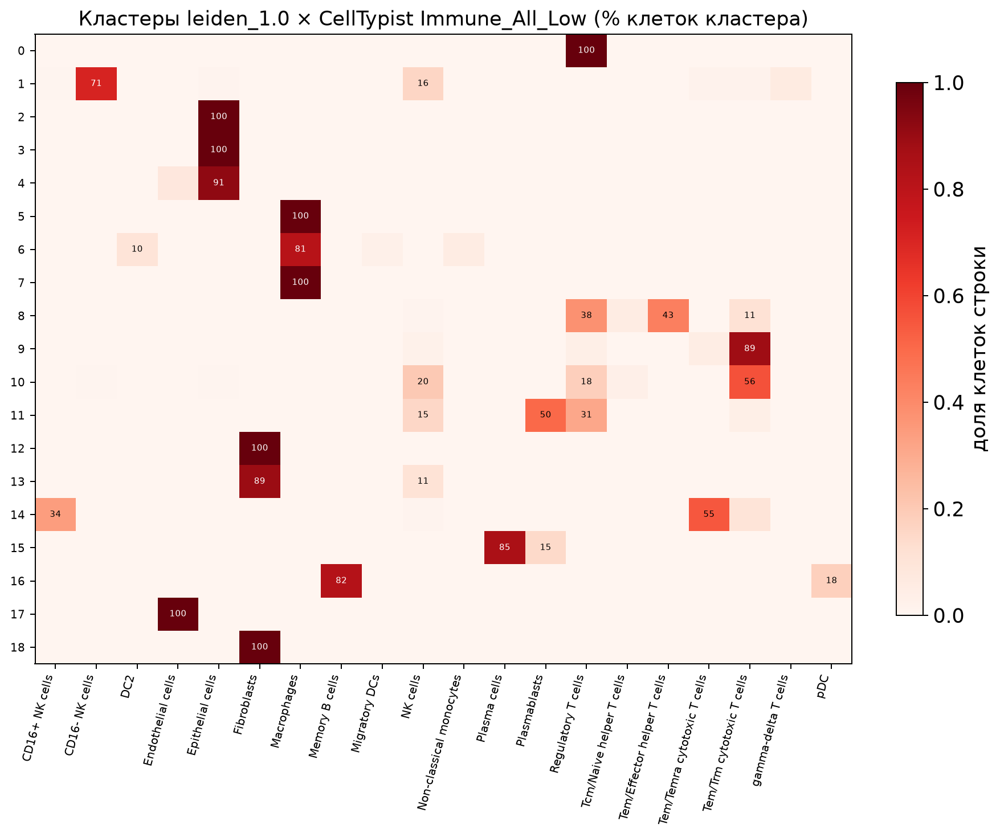

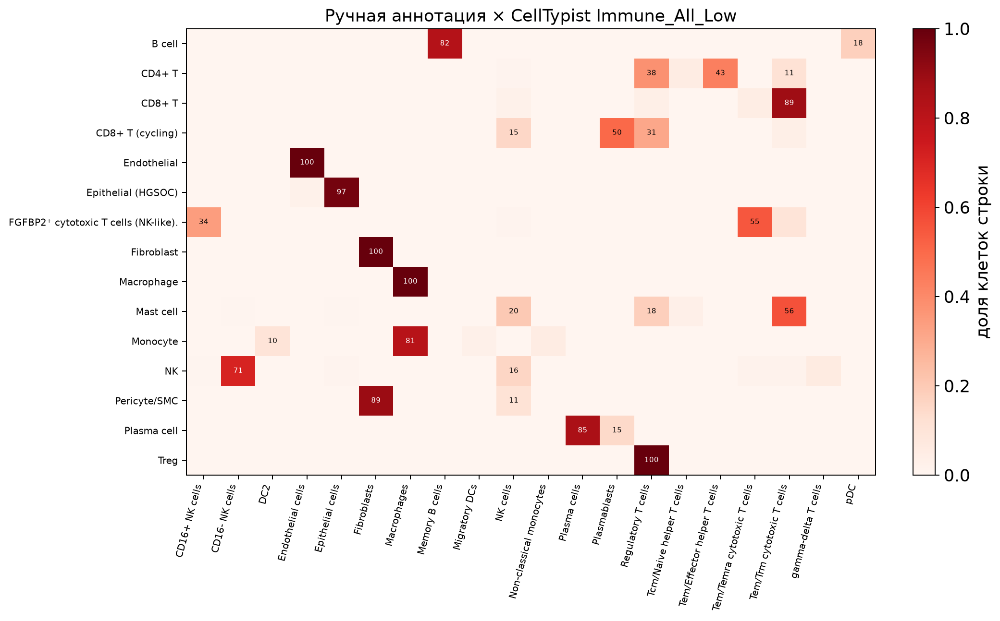

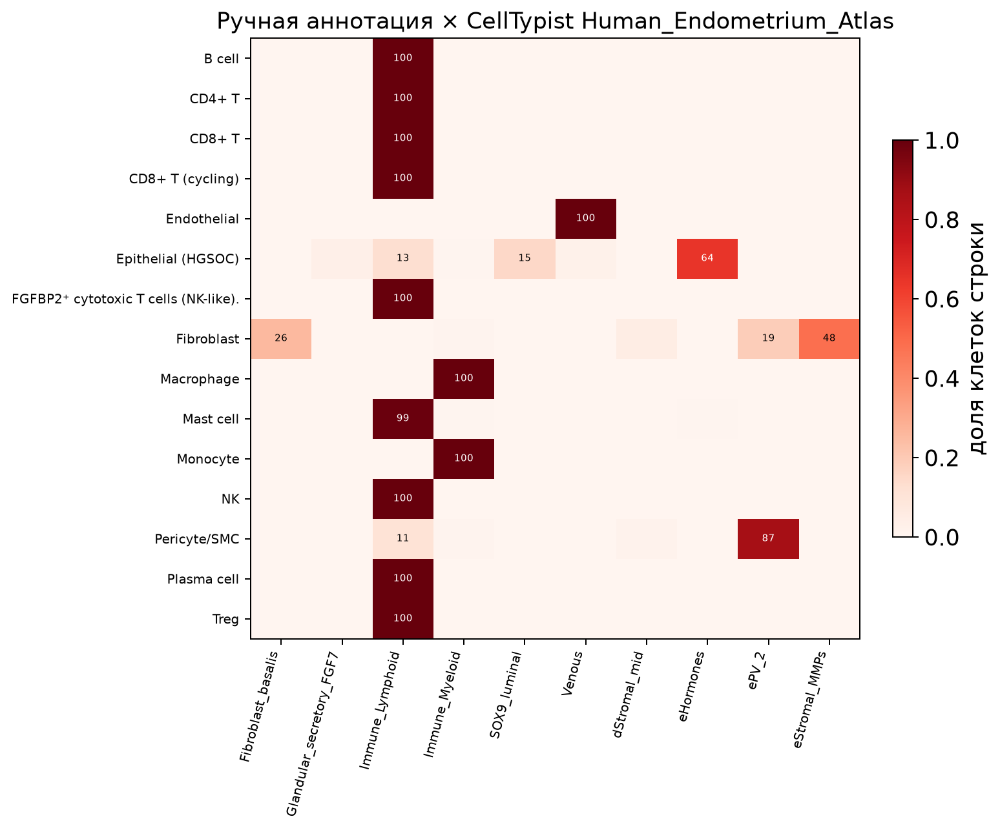

ct_endo_mv,Fibroblast_basalis,Glandular_secretory_FGF7,Immune_Lymphoid,Immune_Myeloid,SOX9_luminal,Venous,dStromal_mid,eHormones,ePV_2,eStromal_MMPs
manual_cell_type,,,,,,,,,,
B cell,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
CD4+ T,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
CD8+ T,0.000000,0.000000,0.999709,0.000291,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
CD8+ T (cycling),0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Endothelial,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
Epithelial (HGSOC),0.000000,0.032527,0.126934,0.005355,0.151527,0.025982,0.000595,0.644982,0.000000,0.000000
FGFBP2⁺ cytotoxic T cells (NK-like).,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Fibroblast,0.257274,0.000000,0.000000,0.010209,0.000510,0.001531,0.047984,0.000000,0.187851,0.480858
Macrophage,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [64]:
def plot_crosstab(rows, cols, normalize="index", min_frac=0.03, title="", annotate_min=0.1):
    ctab = pd.crosstab(rows, cols, normalize=normalize)
    ctab = ctab.loc[:, ctab.max(axis=0) >= min_frac]
    fig, ax = plt.subplots(figsize=(0.38 * ctab.shape[1] + 3.5, 0.32 * ctab.shape[0] + 2))
    im = ax.imshow(ctab.values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(ctab.shape[1]))
    ax.set_xticklabels(ctab.columns, rotation=75, ha="right", fontsize=8)
    ax.set_yticks(range(ctab.shape[0]))
    ax.set_yticklabels(ctab.index, fontsize=8)
    for i, j in zip(*np.where(ctab.values >= annotate_min)):
        v = ctab.values[i, j]
        ax.text(j, i, f"{100 * v:.0f}", ha="center", va="center", fontsize=6,
                color="white" if v > 0.6 else "black")
    ax.grid(False)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.03, label="доля клеток строки")
    plt.show()
    return ctab


ct_manual_immune = pd.crosstab(adata.obs["manual_cell_type"], adata.obs["ct_immune_mv"])
with pd.option_context("display.max_columns", 60):
    display(ct_manual_immune)
plot_crosstab(adata.obs[CLUSTER_KEY], adata.obs["ct_immune_mv"],
              title=f"Кластеры {CLUSTER_KEY} × CellTypist Immune_All_Low (% клеток кластера)")
plot_crosstab(adata.obs["manual_cell_type"], adata.obs["ct_immune_mv"],
              title="Ручная аннотация × CellTypist Immune_All_Low")
plot_crosstab(adata.obs["manual_cell_type"], adata.obs["ct_endo_mv"],
              title="Ручная аннотация × CellTypist Human_Endometrium_Atlas")

### 5.1. Количественное сравнение

Метки CellTypist переводим в наши крупные типы по ключевым словам (например, `Tem/Trm cytotoxic T cells` → `CD8+ T`, `Classical monocytes` → `Monocyte`). Затем для каждого ручного типа считаем долю клеток, у которых автоматическая метка совпадает **по типу** и **по компартменту**. MAIT, γδ T и NKT отнесены к `CD8+ T`, потому что по транскриптому это цитотоксические T-клетки.

In [65]:
CT_RULES = [   # (регулярное выражение по метке CellTypist, наш тип); порядок важен
    (r"regulatory t|treg", "Treg"),
    (r"helper t|cd4|follicular helper|type 1 helper|type 17 helper|th1|th17", "CD4+ T"),
    (r"cytotoxic t|cd8|mait|gamma-delta|nkt|crtam", "CD8+ T"),
    (r"\bnk\b|nk cells|\bilc|unk", "NK"),
    (r"plasma", "Plasma cell"),
    (r"\bb cell|b cells|naive b|memory b|germinal center b|pro-b|pre-b", "B cell"),
    (r"macrophage|kupffer|microglia|mono-mac", "Macrophage"),
    (r"monocyte", "Monocyte"),
    (r"pdc|plasmacytoid", "pDC"),
    (r"\bdc\d?\b|dendritic", "cDC"),
    (r"mast", "Mast cell"),
    (r"erythro", "Erythrocyte"),
    (r"epithel|glandular|lumenal|luminal|ciliated|sox9|secretory", "Epithelial (HGSOC)"),
    (r"endothel|lymphatic|venous|arterial|capillary", "Endothelial"),
    (r"pericyte|smooth muscle|smc|perivascular|\bpv\b|mural|myofibro", "Pericyte/SMC"),
    (r"fibroblast|strom|decidu|mesenchym", "Fibroblast"),
    (r"t cell|t cells|thymocyte", "CD4+ T"),   # прочие T (в т. ч. cycling) — по компартменту T/NK
]


def map_ct_label(label):
    low = str(label).lower()
    for pattern, our in CT_RULES:
        if re.search(pattern, low):
            return our
    return "Other"


for prefix in ("ct_immune", "ct_endo"):
    uniq = adata.obs[f"{prefix}_mv"].cat.categories
    mapping = {u: map_ct_label(u) for u in uniq}
    adata.obs[f"{prefix}_type"] = adata.obs[f"{prefix}_mv"].astype(str).map(mapping).astype("category")
    adata.obs[f"{prefix}_compartment"] = (adata.obs[f"{prefix}_type"].astype(str)
                                          .map(COMPARTMENT).fillna("Other").astype("category"))
    print(f"{prefix}: перевод меток в наши типы")
    print(pd.Series(mapping).sort_values().to_string(), "\n")

manual_base = adata.obs["manual_cell_type"].astype(str).map(base_type)
agree = pd.DataFrame({
    "клеток": manual_base.value_counts(),
    "Immune_All_Low: тип совпал": (manual_base == adata.obs["ct_immune_type"].astype(str)).groupby(manual_base).mean(),
    "Immune_All_Low: компартмент совпал": (adata.obs["compartment"].astype(str) == adata.obs["ct_immune_compartment"].astype(str)).groupby(manual_base).mean(),
    "Endometrium: тип совпал": (manual_base == adata.obs["ct_endo_type"].astype(str)).groupby(manual_base).mean(),
    "Immune_All_Low: медиана уверенности": adata.obs["ct_immune_conf"].groupby(manual_base).median(),
}).sort_values("клеток", ascending=False)
display(agree.style.format({c: "{:.0%}" for c in agree.columns if "совпал" in c}
                           | {"Immune_All_Low: медиана уверенности": "{:.2f}"}))

immune_mask = adata.obs["compartment"].isin(["T/NK", "B/Plasma", "Myeloid/DC", "Mast"])
print(f"Среди иммунных клеток тип совпал у "
      f"{(manual_base[immune_mask] == adata.obs.loc[immune_mask, 'ct_immune_type'].astype(str)).mean():.1%}, "
      f"компартмент у {(adata.obs.loc[immune_mask, 'compartment'].astype(str) == adata.obs.loc[immune_mask, 'ct_immune_compartment'].astype(str)).mean():.1%}")

ct_immune: перевод меток в наши типы
Memory B cells                             B cell
Tem/Effector helper T cells                CD4+ T
Tcm/Naive helper T cells                   CD4+ T
Tem/Trm cytotoxic T cells                  CD8+ T
Tem/Temra cytotoxic T cells                CD8+ T
gamma-delta T cells                        CD8+ T
Endothelial cells                     Endothelial
Epithelial cells               Epithelial (HGSOC)
Fibroblasts                            Fibroblast
Macrophages                            Macrophage
Non-classical monocytes                  Monocyte
CD16+ NK cells                                 NK
NK cells                                       NK
ILC3                                           NK
CD16- NK cells                                 NK
Migratory DCs                               Other
Plasmablasts                          Plasma cell
Plasma cells                          Plasma cell
Regulatory T cells                           Treg
DC2          

,клеток,Immune_All_Low: тип совпал,Immune_All_Low: компартмент совпал,Endometrium: тип совпал,Immune_All_Low: медиана уверенности
manual_cell_type,,,,,
Epithelial (HGSOC),5042,97%,97%,18%,1.00
CD8+ T,4142,78%,91%,0%,0.67
CD4+ T,2823,48%,100%,0%,0.57
NK,2628,89%,99%,0%,0.48
Macrophage,2485,100%,100%,0%,0.88
Mast cell,2208,0%,0%,0%,0.20
Fibroblast,1959,100%,100%,80%,0.99
Monocyte,1557,5%,97%,0%,0.66
Treg,1214,100%,100%,0%,1.00


Среди иммунных клеток тип совпал у 64.1%, компартмент у 84.8%


**Ответы на вопросы** 

- **Где аннотации совпали?** В группах, где есть хорошо известные маркеры + достаточное число клеток в образце.
- **Где расхождения и с чем они связаны.**
  1. **Неиммунные клетки (эпителий, фибробласты, эндотелий)** модель `Immune_All_Low` в принципе не может назвать правильно. Логистическая регрессия всё равно выбирает «ближайший» иммунный класс, но с низкой уверенностью (см. violin по компартментам).
  2. **Модель эндометрия** называет эпителий и строму, но в терминах эндометрия (железистый, люминальный, реснитчатый эпителий, стромальные клетки, перициты). Опухолевых состояний (EMT, CNV-специфичных программ) в референсе нет, поэтому опухолевый эпителий распределяется между «нормальными» эпителиальными классами.
  3. **Внутри T-клеток** граница CD4/CD8/Treg и «памяти/эффекторов» плавная. Специфичные для опухоли состояния (истощённые `PDCD1`⁺`HAVCR2`⁺`CXCL13`⁺, TRM `ITGAE`⁺) в обучающих данных представлены слабо. CellTypist относит их к ближайшим «нормальным» классам (`Tem/Trm cytotoxic T cells`), а наш маркерный подход — к `CD8+ T`.
  4. **Гранулярность.** У CellTypist 98 классов, у нас около 15. Часть «расхождений» на самом деле означает, что CellTypist дробит наш тип на подтипы.
  5. **Majority voting** сглаживает метки внутри over-кластеров: редкие клетки внутри крупного кластера получают метку большинства.
- **Какая аннотация обоснованнее?** Для **иммунных** клеток CellTypist даёт более детальные и воспроизводимые метки, и при высокой уверенности (`conf > 0.5`) им можно доверять, используя их для уточнения подтипов. Для **неиммунных** клеток обоснованнее ручная аннотация по маркерам: подходящего референса нет, а модель эндометрия годится лишь как грубая проверка компартмента. Лучший вариант — комбинация: компартмент определяем вручную по маркерам, подтипы иммунных клеток уточняем по CellTypist.

---
## Задание 6. Субкластеризация T/NK-клеток

**Почему T/NK.** Это самый крупный иммунный компартмент TME HGSOC, и он заведомо неоднороден. Известно несколько функциональных состояний с ясными маркерами:
- наивные/центральные памяти: `CCR7`, `SELL`, `TCF7`;
- Treg: `FOXP3`, `CTLA4`;
- эффекторные памяти CD8: `GZMK`;
- тканерезидентные CD8 (TRM): `ITGAE`, `ZNF683`;
- истощённые CD8 (TEX): `PDCD1`, `HAVCR2`, `LAG3`, `TOX`, `CXCL13`;
- NK: `KLRF1`, `FCGR3A`;
- пролиферирующие клетки.

Авторы статьи отдельно описывают CD8⁺ TRM и TEX с высокой экспрессией `TIGIT`, так что результат можно сверить с публикацией.

**Что пересчитываем.** HVG, PCA, Harmony, граф, UMAP и Leiden считаем **только на T/NK-клетках**. Глобальные HVG отражали различия между компартментами (эпителий против иммунных и т. п.), а внутри T-клеток информативны другие гены. Из HVG исключаем гены вариабельных сегментов TCR/BCR (`TRAV…`, `TRBV…`, `IGHV…`), митохондриальные и рибосомные гены: TCR-гены специфичны для клонотипа и разбили бы клетки на кластеры по клонам, а не по функциональному состоянию.

In [66]:
SUB_COMPARTMENT = "T/NK"
sub_mask = adata.obs["compartment"] == SUB_COMPARTMENT
print(f"Клеток в компартменте {SUB_COMPARTMENT}: {sub_mask.sum()}")
assert sub_mask.sum() >= 100, "Слишком мало клеток; проверьте аннотацию или выберите другой компартмент"

adata_t = adata[sub_mask].copy()
adata_t.obsm["X_umap_global"] = adata_t.obsm["X_umap"].copy()
for k in ["neighbors", "umap", "pca", "wilcoxon", "hvg"]:
    adata_t.uns.pop(k, None)
for k in list(adata_t.obsp.keys()):
    del adata_t.obsp[k]

SUB_EXCLUDE = r"^(TR[ABGD][VJ]\d|IG[HKL][VJ]\d|MT-|RP[SL]\d)"
try:
    sc.pp.highly_variable_genes(adata_t, n_top_genes=2000, flavor="seurat_v3",
                                layer="counts", batch_key="sample")
except Exception as e:
    print("seurat_v3 с batch_key не сработал:", type(e).__name__, "-> считаю без batch_key")
    sc.pp.highly_variable_genes(adata_t, n_top_genes=2000, flavor="seurat_v3", layer="counts")
excluded = adata_t.var["highly_variable"] & adata_t.var_names.str.match(SUB_EXCLUDE)
adata_t.var.loc[excluded, "highly_variable"] = False
print(f"HVG T/NK: {int(adata_t.var['highly_variable'].sum())} (исключено TCR/BCR/MT/RP: {int(excluded.sum())})")

Клеток в компартменте T/NK: 10807
extracting highly variable genes
HVG T/NK: 1960 (исключено TCR/BCR/MT/RP: 40)


computing PCA
    with n_comps=30
    finished (0:00:00)


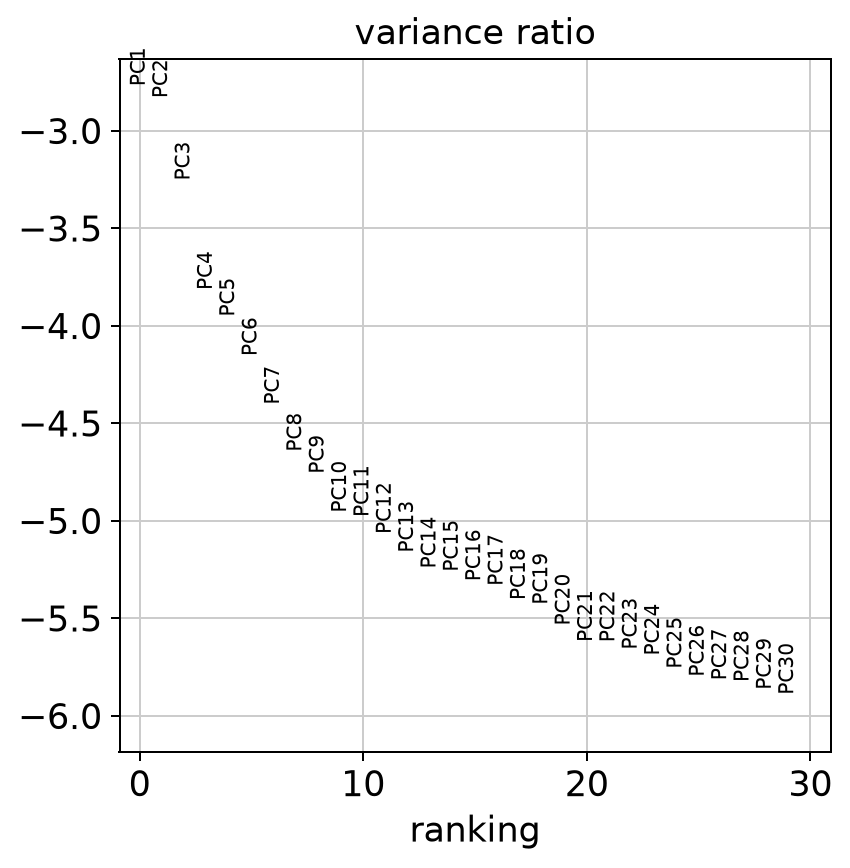

computing neighbors
    finished (0:00:01)
computing UMAP
    finished (0:00:05)
running Leiden clustering
    finished (0:00:00)
Субкластеров: 10


sub_leiden,0,1,2,3,4,5,6,7,8,9
клеток,1822,1248,2132,2135,170,236,943,502,1229,390


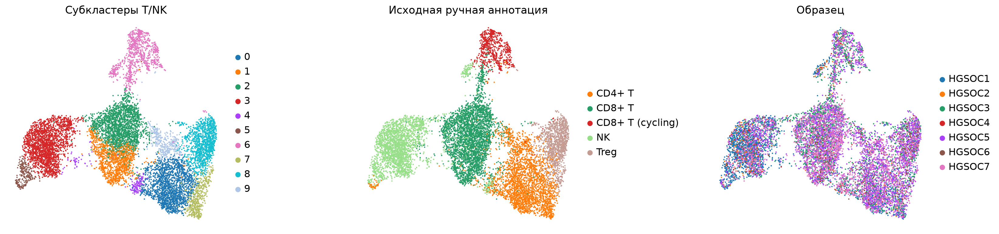

In [67]:
SUB_NPCS = 20
SUB_RES = 0.6
sc.tl.pca(adata_t, n_comps=min(30, adata_t.n_obs - 1), mask_var="highly_variable",
          svd_solver="arpack", random_state=SEED)
sc.pl.pca_variance_ratio(adata_t, n_pcs=30, log=True)

SUB_REP = "X_pca"
if USE_HARMONY and adata_t.obs["sample"].nunique() > 1:
    try:
        SUB_REP = run_harmony(adata_t, "sample", SUB_NPCS)
    except ImportError:
        pass
sc.pp.neighbors(adata_t, n_neighbors=15, use_rep=SUB_REP,
                n_pcs=SUB_NPCS if SUB_REP == "X_pca" else None, random_state=SEED)
sc.tl.umap(adata_t, min_dist=0.3, random_state=SEED)
sc.tl.leiden(adata_t, resolution=SUB_RES, key_added="sub_leiden", flavor="igraph",
             n_iterations=2, directed=False, random_state=SEED)
print("Субкластеров:", adata_t.obs["sub_leiden"].nunique())
display(adata_t.obs["sub_leiden"].value_counts().sort_index().rename("клеток").to_frame().T)

sc.pl.umap(adata_t, color=["sub_leiden", "manual_cell_type", "sample"], ncols=3, wspace=0.45, size=12,
           legend_loc="right margin",
           title=["Субкластеры T/NK", "Исходная ручная аннотация", "Образец"])

ranking genes
    finished (0:00:15)


,top DE genes
group,
0,"IL7R, CD40LG, TPT1, CCR7, LTB, KLF2, MAL, GPR183"
1,"GZMK, CD8A, GZMH, GZMA, KLRG1, CD8B, CCL4, CST7"
2,"CD8A, CD8B, LAG3, GZMB, GZMH, CCL5, GZMA, CXCL13"
3,"TYROBP, FCER1G, TRDC, GNLY, KRT81, KLRD1, TXK, XCL1"
4,"TRGC2, XCL1, ZNF683, XCL2, LEF1, KLRC2, FCRL6, NCR3"
5,"COL23A1, ZBTB16, SCART1, TTLL10, FCER1G, TMIGD2, TRDC, CXXC5"
6,"MKI67, TYMS, TOP2A, ASPM, ZWINT, GTSE1, CDK1, KIFC1"
7,"IL7R, XIST, LTB, JUNB, FOS, NABP1, KLF2, JUN"
8,"FOXP3, IL2RA, RTKN2, TNFRSF4, CTLA4, TBC1D4, LAIR2, IL32"


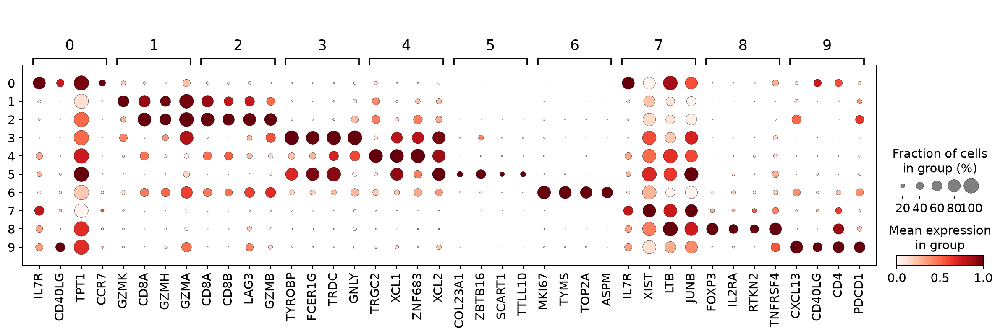

In [68]:
sc.tl.rank_genes_groups(adata_t, groupby="sub_leiden", method="wilcoxon", use_raw=False,
                        tie_correct=True, pts=True, key_added="wilcoxon_sub")
sub_markers = sc.get.rank_genes_groups_df(adata_t, group=None, key="wilcoxon_sub")
sub_markers.to_csv(RESULTS_DIR / "markers_TNK_subclusters.csv", index=False)
sub_markers_f = sub_markers[
    (sub_markers["pvals_adj"] < 0.05) & (sub_markers["logfoldchanges"] > 0.75)
    & (sub_markers["pct_nz_group"] >= 0.2) & ~sub_markers["names"].str.match(NOISE_GENES + "|" + SUB_EXCLUDE)
].sort_values(["group", "scores"], ascending=[True, False])

sub_clusters = list(adata_t.obs["sub_leiden"].cat.categories)
sub_top = (sub_markers_f.groupby("group", observed=True).head(8)
           .groupby("group", observed=True)["names"].apply(", ".join)
           .reindex(sub_clusters).fillna("—"))
with pd.option_context("display.max_colwidth", 200):
    display(sub_top.rename("top DE genes").to_frame())

sub_dot = {str(g): list(d["names"]) for g, d in
           sub_markers_f.groupby("group", observed=True).head(4).groupby("group", observed=True) if len(d)}
sc.pl.dotplot(adata_t, var_names={c: sub_dot[c] for c in sub_clusters if c in sub_dot},
              groupby="sub_leiden", standard_scale="var")

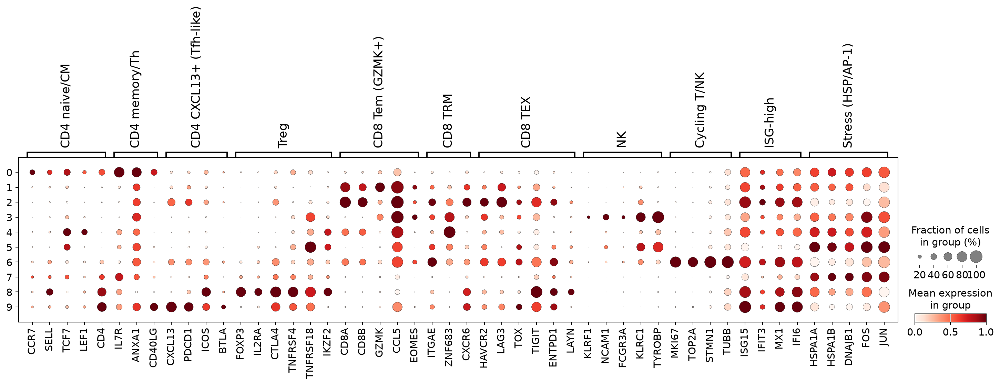

,draft,best,z_best,second,z_second,top DE
0,CD4 memory/Th,CD4 memory/Th,1.54,CD4 naive/CM,1.30,"IL7R, CD40LG, TPT1, CCR7, LTB, KLF2, MAL, GPR183"
1,CD8 Tem (GZMK+),CD8 Tem (GZMK+),1.65,CD8 TRM,0.54,"GZMK, CD8A, GZMH, GZMA, KLRG1, CD8B, CCL4, CST7"
2,CD8 TRM,CD8 TRM,1.41,CD8 TEX,1.35,"CD8A, CD8B, LAG3, GZMB, GZMH, CCL5, GZMA, CXCL13"
3,NK,NK,2.59,CD8 Tem (GZMK+),0.41,"TYROBP, FCER1G, TRDC, GNLY, KRT81, KLRD1, TXK,..."
4,CD4 naive/CM,CD4 naive/CM,0.43,Stress (HSP/AP-1),0.43,"TRGC2, XCL1, ZNF683, XCL2, LEF1, KLRC2, FCRL6,..."
5,Stress (HSP/AP-1),Stress (HSP/AP-1),1.41,NK,0.66,"COL23A1, ZBTB16, SCART1, TTLL10, FCER1G, TMIGD..."
6,Cycling T/NK,Cycling T/NK,2.98,ISG-high,0.73,"MKI67, TYMS, TOP2A, ASPM, ZWINT, GTSE1, CDK1, ..."
7,Stress (HSP/AP-1),Stress (HSP/AP-1),1.45,CD4 naive/CM,0.62,"IL7R, XIST, LTB, JUNB, FOS, NABP1, KLF2, JUN"
8,Treg,Treg,2.25,ISG-high,0.73,"FOXP3, IL2RA, RTKN2, TNFRSF4, CTLA4, TBC1D4, L..."
9,CD4 CXCL13+ (Tfh-like),CD4 CXCL13+ (Tfh-like),2.06,CD4 memory/Th,1.10,"CXCL13, CD40LG, CD4, PDCD1, CYSLTR1, CD2, NMB,..."


In [69]:
T_STATES = {
    "CD4 naive/CM":      ["CCR7", "SELL", "TCF7", "LEF1", "CD4"],
    "CD4 memory/Th":     ["CD4", "IL7R", "ANXA1", "CD40LG"],
    "CD4 CXCL13+ (Tfh-like)": ["CD4", "CXCL13", "PDCD1", "ICOS", "BTLA"],
    "Treg":              ["FOXP3", "IL2RA", "CTLA4", "TNFRSF4", "TNFRSF18", "IKZF2"],
    "CD8 Tem (GZMK+)":   ["CD8A", "CD8B", "GZMK", "CCL5", "EOMES"],
    "CD8 TRM":           ["CD8A", "ITGAE", "ZNF683", "CXCR6"],
    "CD8 TEX":           ["CD8A", "PDCD1", "HAVCR2", "LAG3", "TOX", "TIGIT", "ENTPD1", "LAYN"],
    "NK":                ["KLRF1", "NCAM1", "FCGR3A", "KLRC1", "TYROBP"],
    "Cycling T/NK":      ["MKI67", "TOP2A", "STMN1", "TUBB"],
    "ISG-high":          ["ISG15", "IFIT3", "MX1", "IFI6"],
    "Stress (HSP/AP-1)": ["HSPA1A", "HSPA1B", "DNAJB1", "FOS", "JUN"],
}
t_present = {k: [g for g in v if g in adata_t.var_names] for k, v in T_STATES.items()}
t_present = {k: v for k, v in t_present.items() if v}

t_scores, t_pct = marker_set_zscores(adata_t, "sub_leiden", t_present)
t_draft = assign_labels(t_scores, {k: "T" for k in t_present}, min_z=0.4, min_margin=0.0, state_sets=())
SUB_OVERRIDES = {}     # ручные правки субкластеров, например {"5": "CD8 TEX"}
sub_labels = {**t_draft["draft"].to_dict(), **SUB_OVERRIDES}
adata_t.obs["t_subtype"] = adata_t.obs["sub_leiden"].astype(str).map(sub_labels).astype("category")

seen, t_dot = set(), {}
for k, gs in t_present.items():
    uniq = [g for g in gs if g not in seen]
    seen.update(uniq)
    if uniq:
        t_dot[k] = uniq
sc.pl.dotplot(adata_t, var_names=t_dot, groupby="sub_leiden", standard_scale="var")
display(pd.concat([t_draft.round(2), sub_top.rename("top DE")], axis=1))

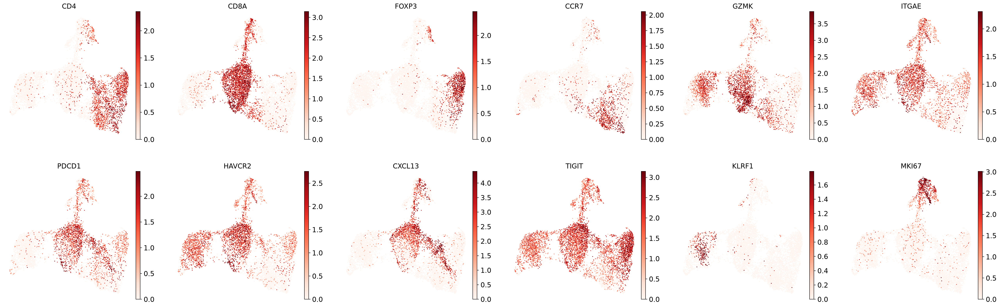

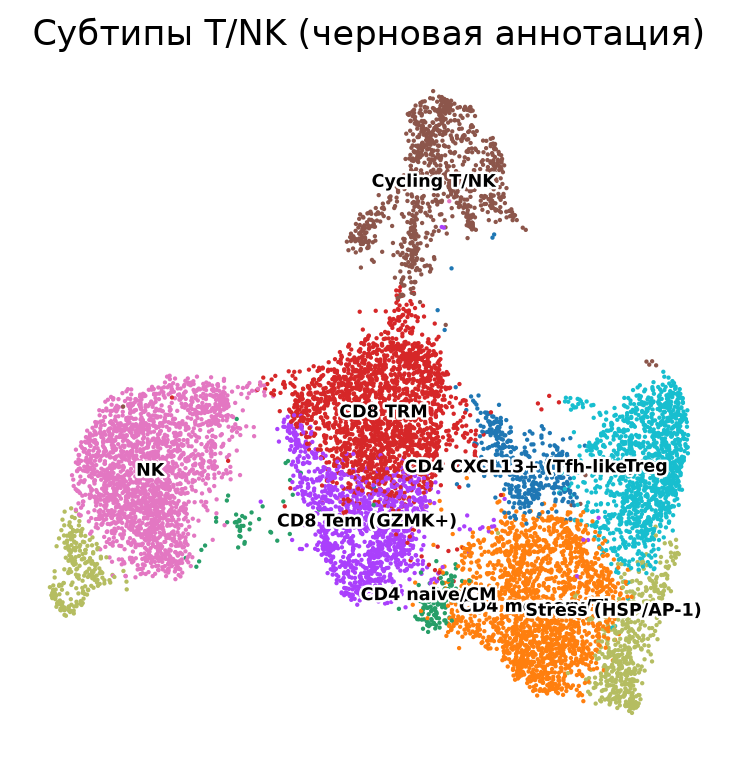

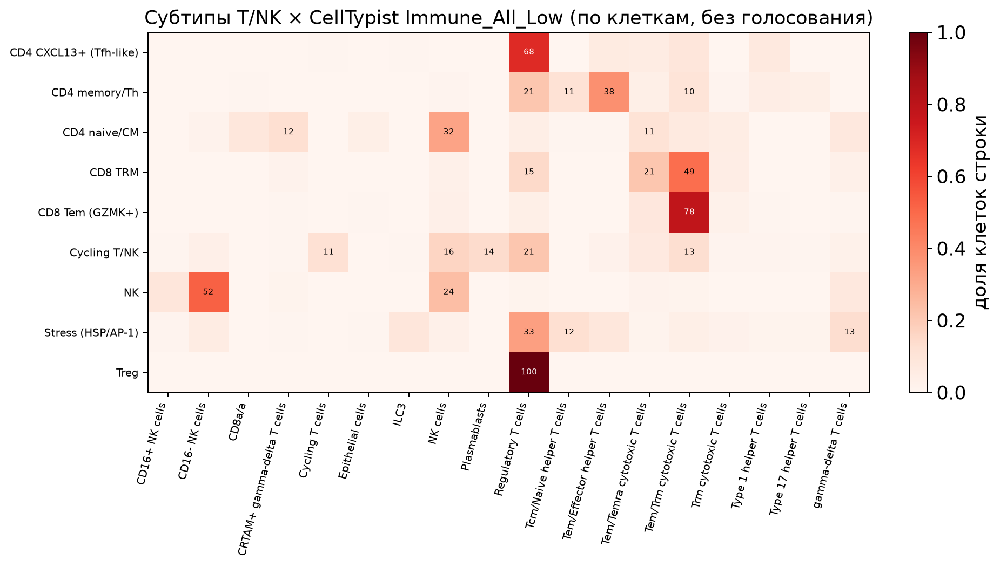

In [70]:
t_umap_genes = [g for g in ["CD4", "CD8A", "FOXP3", "CCR7", "GZMK", "ITGAE", "PDCD1", "HAVCR2",
                            "CXCL13", "TIGIT", "KLRF1", "MKI67"] if g in adata_t.var_names]
sc.pl.umap(adata_t, color=t_umap_genes, ncols=6, cmap="Reds", vmax="p99", size=10)
sc.pl.umap(adata_t, color="t_subtype", legend_loc="on data", legend_fontsize=7,
           legend_fontoutline=2, size=12, title="Субтипы T/NK (черновая аннотация)")

plot_crosstab(adata_t.obs["t_subtype"], adata_t.obs["ct_immune_cell"],
              title="Субтипы T/NK × CellTypist Immune_All_Low (по клеткам, без голосования)")

# переносим субтипы в общий объект
adata.obs["fine_cell_type"] = adata.obs["manual_cell_type"].astype(str)
adata.obs.loc[adata_t.obs_names, "fine_cell_type"] = adata_t.obs["t_subtype"].astype(str).values
adata.obs["fine_cell_type"] = adata.obs["fine_cell_type"].astype("category")

**Ответы на вопросы** 

- **Удалось ли разделить популяцию на интерпретируемые субпопуляции?** Да:
  - CD4 naive/CM: `CCR7`, `SELL`, `TCF7`;
  - Treg: `FOXP3`, `CTLA4`, `TNFRSF4`;
  - CD8 Tem: `GZMK`;
  - CD8 TRM: `ITGAE`, `ZNF683`, `CXCR6`;
  - CD8 TEX: `PDCD1`, `HAVCR2`, `LAG3`, `TOX`, `TIGIT`, `CXCL13`;
  - NK: `KLRF1`, `FCGR3A`;
  - пролиферирующие и ISG-high клетки.

  Совпадение с CellTypist (`Regulatory T cells`, `Tcm/Naive helper T cells`, `Tem/Trm cytotoxic T cells`, `CD16+ NK cells`) — независимое подтверждение. Отдельно стоит отметить TEX с высоким `TIGIT`: именно эту популяцию авторы статьи рассматривают как мишень (блокада TIGIT уменьшала рост опухоли в мышиной модели).
- **Какие гены отличают субкластеры?** См. таблицу топ-DE генов и dotplot. Различия задают гены дифференцировки (`CCR7`/`SELL` против `GZMK`), тканевой резидентности (`ITGAE`, `ZNF683`), коингибиторные рецепторы (`PDCD1`, `HAVCR2`, `TIGIT`, `LAG3`), транскрипционные факторы (`FOXP3`, `TOX`, `TCF7`) и гены клеточного цикла.
- **Почему различия были незаметны при общей кластеризации?**
  1. **Глобальные HVG и ГК** отражают самые крупные различия: эпителий против стромы против иммунных клеток. Гены, различающие состояния T-клеток (`ITGAE`, `TOX`, `PDCD1`), имеют небольшой вклад в общую дисперсию, не попадают в топ HVG или «тонут» в первых ГК.
  2. **Разрешение графа.** Клеточные состояния T-клеток образуют непрерывный континуум с малыми расстояниями. На глобальном графе 15 соседей клетки почти всегда тоже T-клетки, и для разбиения внутри компартмента нужен γ, при котором остальные ткани дробятся на шум.
  3. После субсета **Harmony и PCA** перенастраиваются только на T-клеточную вариабельность.
- **Если убедительных субпопуляций не нашлось**, возможные причины: мало T-клеток, низкая глубина (`FOXP3`, `CXCL13` и `PDCD1` детектируются в небольшой доле клеток из-за dropout), состояния непрерывны (лучше описывать их скорами программ, а не дискретными кластерами), кластеры по стрессу диссоциации (`HSPA1A`, `FOS`) — артефакт, а не биология.

---
## Задание 7. Генные программы

| Программа | Гены | Источник |
|---|---|---|
| **Цитотоксичность** | `NKG7`, `PRF1`, `GZMA`, `GZMB`, `GZMH`, `GNLY` | эффекторные молекулы цитотоксических гранул (перфорин, гранзимы, гранулизин); набор из задания, дополнен `GZMA`/`GZMH` |
| **Интерфероновый ответ I типа** | `ISG15`, `IFIT2`, `IFIT3`, `IFI44`, `IFI44L`, `MX1`, `OAS1`, `OASL`, `RSAD2`, `HERC6`, `CMPK2`, `USP18`, `EPSTI1` | ядро интерферон-стимулируемых генов из MSigDB **HALLMARK_INTERFERON_ALPHA_RESPONSE** (Liberzon et al., *Cell Syst* 2015) |
| **Пролиферация** | 43 гена S-фазы + 54 гена G2/M | Tirosh et al., *Science* 2016 (те же списки в `Seurat::cc.genes`); старые и новые HGNC-символы (`MLF1IP`/`CENPU`, `FAM64A`/`PIMREG`, `HN1`/`JPT1`) |

Почему именно эти программы для HGSOC:
- **Цитотоксичность** разделяет эффекторные CD8 и NK, с одной стороны, и CD4 и Treg — с другой.
- **IFN-ответ** в опухолях яичника различается между пациентками и связан с инфильтрацией T-клетками (опухоли с высокой инфильтрацией отличаются высоким IFN-ответом опухолевых клеток).
- **Пролиферация** выделяет делящиеся опухолевые клетки и клональную экспансию T-клеток.

`sc.tl.score_genes` вычитает из средней экспрессии набора среднюю экспрессию контрольных генов того же уровня экспрессии, поэтому score можно сравнивать между клетками разной глубины.

cytotoxic_score: найдено 6 из 6 генов
computing score 'cytotoxic_score'
    finished (0:00:00)
ifn_score: найдено 13 из 13 генов
computing score 'ifn_score'
    finished (0:00:00)
prolif_score: найдено 97 из 100 генов
computing score 'prolif_score'
    finished (0:00:00)
calculating cell cycle phase
computing score 'S_score'
    finished (0:00:00)
computing score 'G2M_score'
    finished (0:00:00)
Делящихся клеток (max(S_score, G2M_score) > 0.3): 6.0%


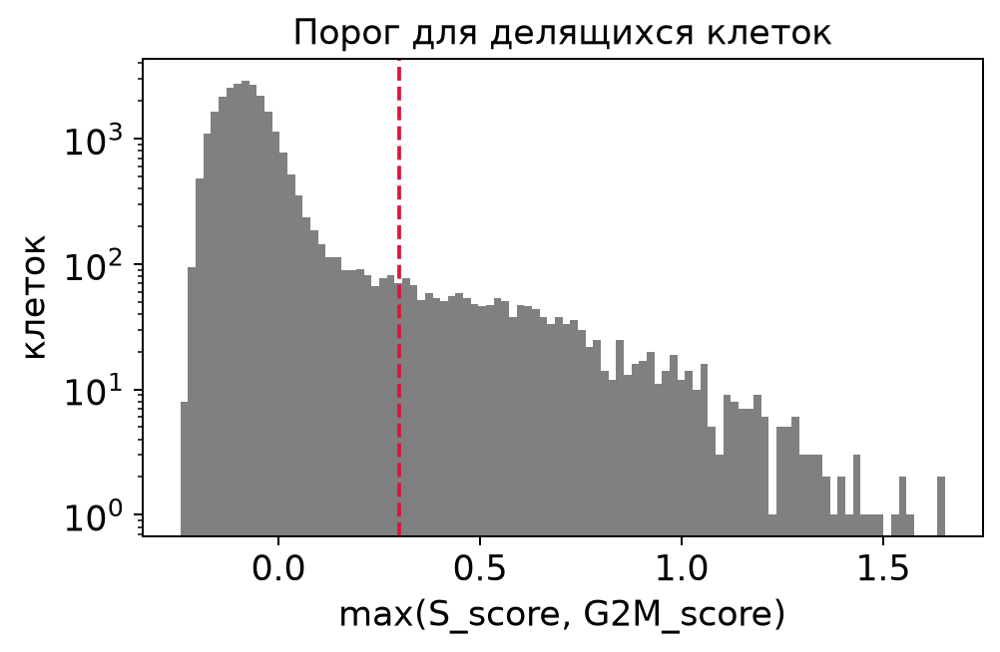

In [71]:
S_GENES = ["MCM5", "PCNA", "TYMS", "FEN1", "MCM2", "MCM4", "RRM1", "UNG", "GINS2", "MCM6", "CDCA7",
           "DTL", "PRIM1", "UHRF1", "MLF1IP", "CENPU", "HELLS", "RFC2", "RPA2", "NASP", "RAD51AP1",
           "GMNN", "WDR76", "SLBP", "CCNE2", "UBR7", "POLD3", "MSH2", "ATAD2", "RAD51", "RRM2",
           "CDC45", "CDC6", "EXO1", "TIPIN", "DSCC1", "BLM", "CASP8AP2", "USP1", "CLSPN", "POLA1",
           "CHAF1B", "BRIP1", "E2F8"]
G2M_GENES = ["HMGB2", "CDK1", "NUSAP1", "UBE2C", "BIRC5", "TPX2", "TOP2A", "NDC80", "CKS2", "NUF2",
             "CKS1B", "MKI67", "TMPO", "CENPF", "TACC3", "FAM64A", "PIMREG", "SMC4", "CCNB2", "CKAP2L",
             "CKAP2", "AURKB", "BUB1", "KIF11", "ANP32E", "TUBB4B", "GTSE1", "KIF20B", "HJURP",
             "CDCA3", "HN1", "JPT1", "CDC20", "TTK", "CDC25C", "KIF2C", "RANGAP1", "NCAPD2", "DLGAP5",
             "CDCA2", "CDCA8", "ECT2", "KIF23", "HMMR", "AURKA", "PSRC1", "ANLN", "LBR", "CKAP5",
             "CENPE", "CTCF", "NEK2", "G2E3", "GAS2L3", "CBX5", "CENPA"]

PROGRAMS = {
    "cytotoxic_score": ["NKG7", "PRF1", "GZMA", "GZMB", "GZMH", "GNLY"],
    "ifn_score": ["ISG15", "IFIT2", "IFIT3", "IFI44", "IFI44L", "MX1", "OAS1", "OASL", "RSAD2",
                  "HERC6", "CMPK2", "USP18", "EPSTI1"],
    "prolif_score": S_GENES + G2M_GENES,
}
PROGRAM_TITLES = {"cytotoxic_score": "Цитотоксичность", "ifn_score": "IFN-ответ I типа",
                  "prolif_score": "Пролиферация (S+G2/M)"}

for name, genes in PROGRAMS.items():
    present = [g for g in dict.fromkeys(genes) if g in adata.var_names]
    print(f"{name}: найдено {len(present)} из {len(set(genes))} генов")
    sc.tl.score_genes(adata, gene_list=present, score_name=name, use_raw=False, random_state=SEED)

sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in S_GENES if g in adata.var_names],
                             g2m_genes=[g for g in G2M_GENES if g in adata.var_names],
                             use_raw=False, random_state=SEED)

# `phase` присваивает S/G2M любой клетке со score > 0, а у неделящихся клеток скоры
# распределены вокруг нуля, поэтому около половины из них получают «S» или «G2M».
# Делящимися считаем только клетки с явно высоким скором.
CYCLING_THR = 0.3
adata.obs["is_cycling"] = adata.obs[["S_score", "G2M_score"]].max(axis=1) > CYCLING_THR
print(f"Делящихся клеток (max(S_score, G2M_score) > {CYCLING_THR}): {adata.obs['is_cycling'].mean():.1%}")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(adata.obs[["S_score", "G2M_score"]].max(axis=1), bins=100, color="grey")
ax.axvline(CYCLING_THR, ls="--", c="crimson")
ax.set(xlabel="max(S_score, G2M_score)", ylabel="клеток", yscale="log", title="Порог для делящихся клеток")
ax.grid(False)
plt.show()

... storing 'phase' as categorical


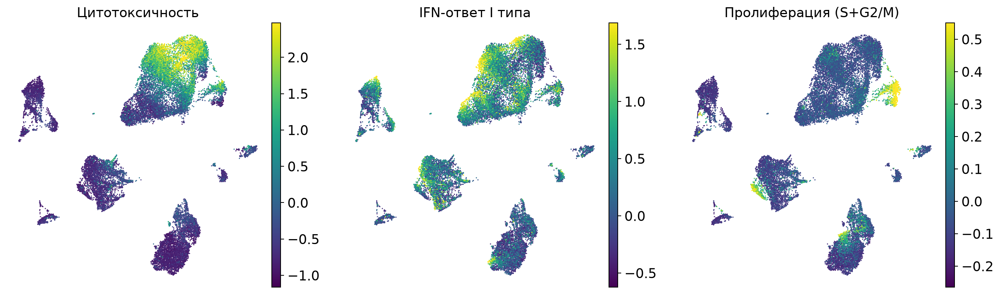

In [72]:
sc.pl.umap(adata, color=list(PROGRAMS), cmap="viridis", vmax="p99", ncols=3, size=6,
           title=[PROGRAM_TITLES[p] for p in PROGRAMS])

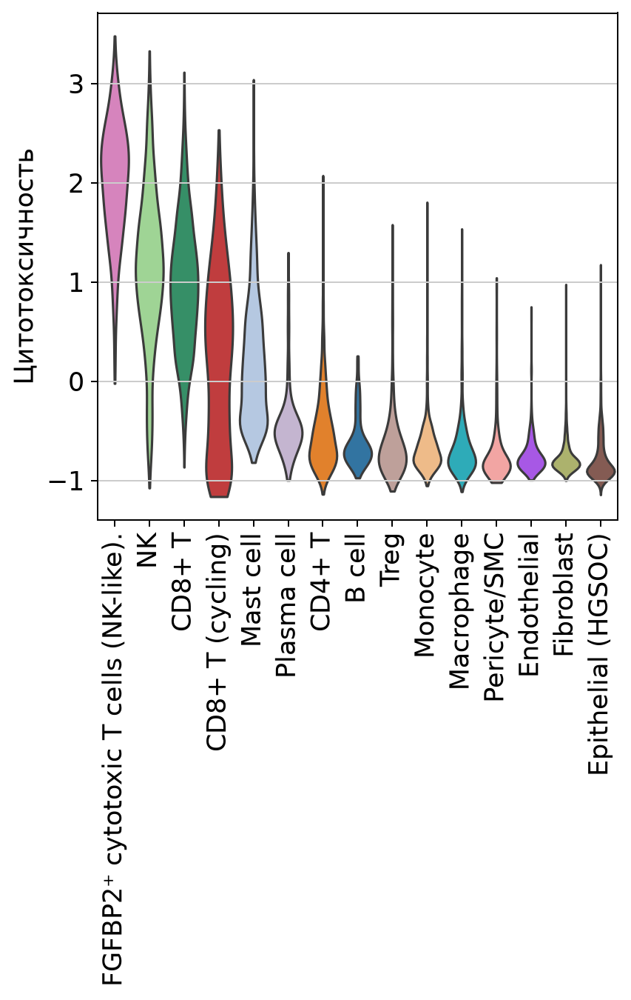

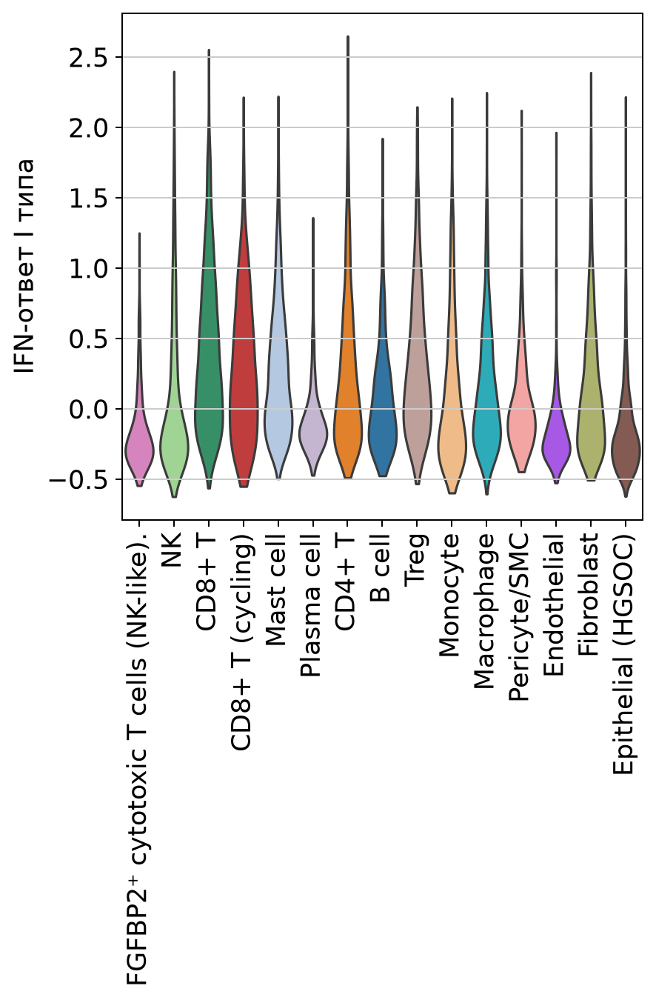

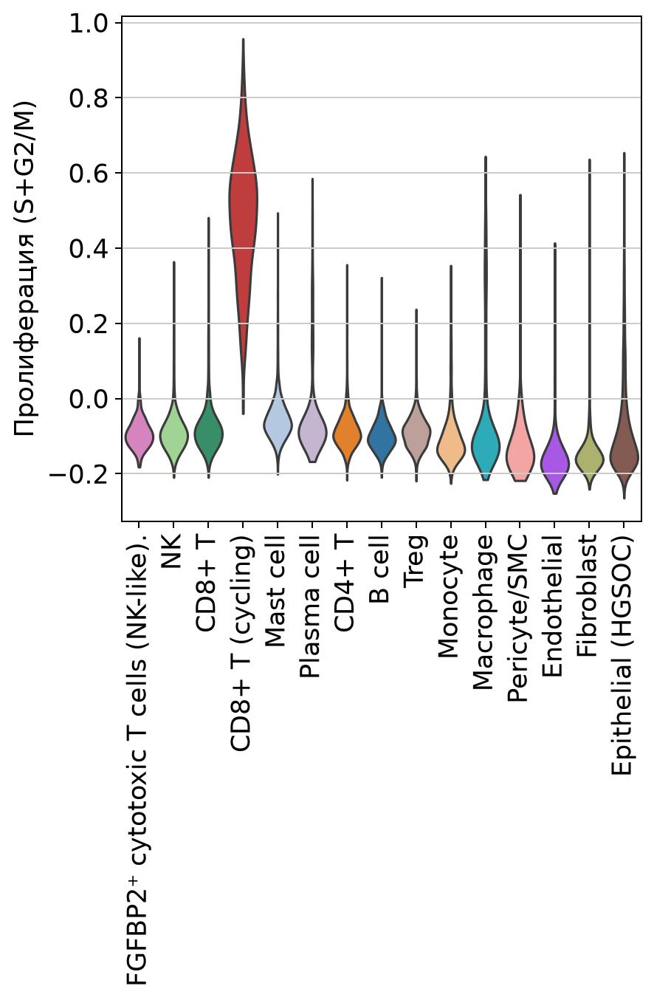

In [73]:
order = (adata.obs.groupby("manual_cell_type", observed=True)["cytotoxic_score"]
         .mean().sort_values(ascending=False).index.tolist())
for p in PROGRAMS:
    sc.pl.violin(adata, p, groupby="manual_cell_type", order=order, rotation=90,
                 stripplot=False, ylabel=PROGRAM_TITLES[p])

In [74]:
prog_by_type = adata.obs.groupby("manual_cell_type", observed=True)[list(PROGRAMS)].mean()
prog_by_type["доля делящихся"] = adata.obs["is_cycling"].groupby(adata.obs["manual_cell_type"], observed=True).mean()
display(prog_by_type.sort_values("cytotoxic_score", ascending=False)
        .style.background_gradient(cmap="viridis", subset=list(PROGRAMS))
        .format("{:.3f}", subset=list(PROGRAMS)).format("{:.0%}", subset=["доля делящихся"]))

for p in PROGRAMS:
    top = prog_by_type[p].sort_values(ascending=False).head(3)
    print(f"{PROGRAM_TITLES[p]}: сильнее всего в " + ", ".join(f"{t} ({v:.2f})" for t, v in top.items()))

,cytotoxic_score,ifn_score,prolif_score,доля делящихся
manual_cell_type,,,,
FGFBP2⁺ cytotoxic T cells (NK-like).,2.005,-0.163,-0.093,1%
NK,1.123,0.068,-0.088,1%
CD8+ T,0.960,0.403,-0.076,3%
CD8+ T (cycling),0.215,0.280,0.477,95%
Mast cell,0.209,0.265,-0.055,1%
Plasma cell,-0.429,-0.083,-0.051,7%
CD4+ T,-0.500,0.241,-0.086,1%
B cell,-0.603,0.067,-0.099,0%
Treg,-0.638,0.304,-0.089,0%


Цитотоксичность: сильнее всего в FGFBP2⁺ cytotoxic T cells (NK-like). (2.00), NK (1.12), CD8+ T (0.96)
IFN-ответ I типа: сильнее всего в CD8+ T (0.40), Treg (0.30), CD8+ T (cycling) (0.28)
Пролиферация (S+G2/M): сильнее всего в CD8+ T (cycling) (0.48), Plasma cell (-0.05), Macrophage (-0.05)


### 7.1. Программы как инструмент уточнения аннотации

Ниже три конкретных примера:
1. **Внутри T/NK**: цитотоксичность и пролиферация по субтипам.
2. **Внутри опухолевого эпителия**: IFN-ответ и пролиферация по пациенткам.
3. **Доля делящихся клеток** (max(S, G2M) > порога) и их фаза по типам: какие «типы» на самом деле содержат делящиеся клетки.

,cytotoxic_score,ifn_score,prolif_score
t_subtype,,,
NK,1.284,0.074,-0.094
CD8 TRM,1.070,0.449,-0.087
CD8 Tem (GZMK+),0.814,0.339,-0.085
Cycling T/NK,0.373,0.262,0.393
CD4 naive/CM,0.146,0.186,-0.095
Stress (HSP/AP-1),-0.423,-0.008,-0.076
CD4 CXCL13+ (Tfh-like),-0.438,0.480,-0.086
CD4 memory/Th,-0.506,0.227,-0.092
Treg,-0.645,0.323,-0.091


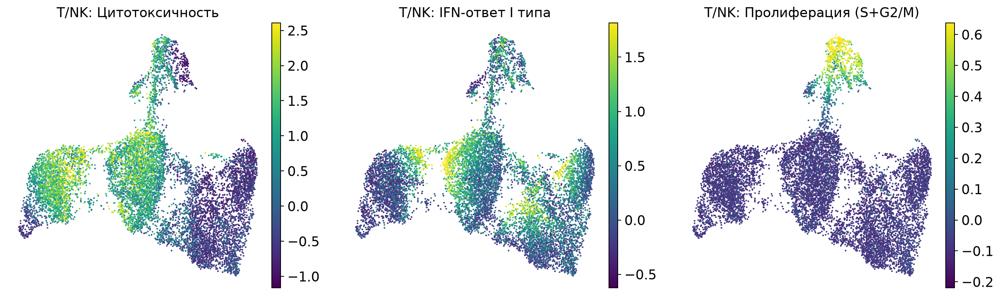

,n_cells,ifn_score,prolif_score,frac_cycling
sample,,,,
HGSOC1,761,-0.175,-0.100,0.042
HGSOC2,1219,-0.262,-0.111,0.043
HGSOC3,322,-0.055,-0.022,0.099
HGSOC4,486,0.018,-0.134,0.019
HGSOC5,259,-0.004,-0.084,0.042
HGSOC6,1412,-0.179,-0.065,0.073
HGSOC7,583,-0.065,-0.056,0.089


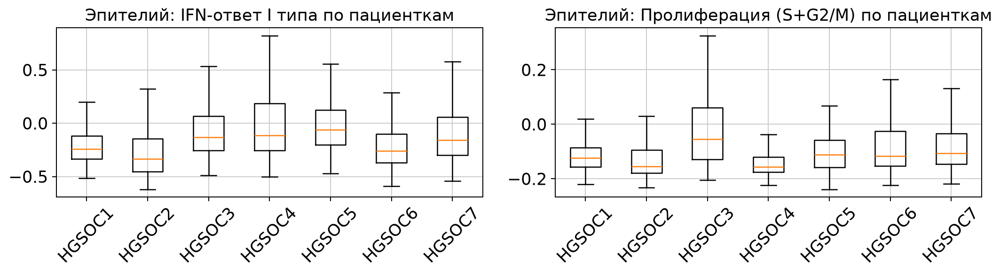

фаза,G2M,S,не делятся
manual_cell_type,,,
CD8+ T (cycling),0.738,0.213,0.048
Macrophage,0.095,0.027,0.878
Plasma cell,0.052,0.015,0.932
Epithelial (HGSOC),0.048,0.010,0.942
Pericyte/SMC,0.028,0.008,0.964
CD8+ T,0.001,0.028,0.970
Endothelial,0.021,0.005,0.974
Monocyte,0.010,0.008,0.982
NK,0.001,0.014,0.985


In [75]:
for p in list(PROGRAMS) + ["phase", "is_cycling"]:
    adata_t.obs[p] = adata.obs.loc[adata_t.obs_names, p].values
t_prog = adata_t.obs.groupby("t_subtype", observed=True)[list(PROGRAMS)].mean()
display(t_prog.sort_values("cytotoxic_score", ascending=False)
        .style.background_gradient(cmap="viridis").format("{:.3f}"))
sc.pl.umap(adata_t, color=list(PROGRAMS), cmap="viridis", vmax="p99", ncols=3, size=12,
           title=[f"T/NK: {PROGRAM_TITLES[p]}" for p in PROGRAMS])

epi = adata.obs[adata.obs["compartment"] == "Epithelial"]
if len(epi) > 0:
    epi_prog = epi.groupby("sample", observed=True).agg(
        n_cells=("ifn_score", "size"), ifn_score=("ifn_score", "mean"),
        prolif_score=("prolif_score", "mean"),
        frac_cycling=("is_cycling", "mean"))
    display(epi_prog.round(3))
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    for ax, p in zip(axes, ["ifn_score", "prolif_score"]):
        data = [epi.loc[epi["sample"] == s, p].values for s in epi_prog.index]
        ax.boxplot(data, showfliers=False)
        ax.set_xticks(range(1, len(epi_prog) + 1))
        ax.set_xticklabels(epi_prog.index, rotation=45)
        ax.set_title(f"Эпителий: {PROGRAM_TITLES[p]} по пациенткам")
    plt.tight_layout()
    plt.show()

cycle_state = np.where(adata.obs["is_cycling"], adata.obs["phase"].astype(str), "не делятся")
cycle_tab = pd.crosstab(adata.obs["manual_cell_type"], pd.Series(cycle_state, index=adata.obs_names, name="фаза"),
                        normalize="index").round(3)
display(cycle_tab.sort_values("не делятся"))

**Главный вопрос: как генные программы помогают уточнить ручную аннотацию?**

Программы отвечают на вопрос «**в каком состоянии** клетка», а маркеры — на вопрос «**какого она типа**». Вместе они разделяют тип и состояние. Примеры (сверьте с выводом выше):
1. **Цитотоксичность** чётко отделяет NK и эффекторные CD8 (`CD8 Tem`, `CD8 TEX`, `CD8 TRM`: высокий score) от CD4 naive/CM и Treg (около нуля). Если кластер с «CD4»-маркерами имеет высокий цитотоксический score, это повод проверить, не смесь ли это с CD8 и NK, или выделить редкие цитотоксические CD4.
2. **Пролиферация** показывает, что кластеры с `MKI67`/`TOP2A` — не отдельный «тип», а делящиеся клетки уже известных типов. Обычно это опухолевый эпителий и T-клетки (клональная экспансия CD8 TEX). Поэтому в аннотации им дана метка «тип (cycling)», а не отдельный тип. Разная доля делящихся клеток в эпителии разных пациенток — пример межопухолевой гетерогенности.
3. **IFN-ответ** выделяет ISG-high состояние, которое иначе могло бы быть принято за отдельный тип (в T-клетках, макрофагах, эпителии). В опухолевых клетках он сильно различается между пациентками. Это согласуется с литературой: опухоли яичника с высокой T-клеточной инфильтрацией отличаются высоким IFN-ответом опухолевых клеток.

Высокий gene score означает только относительно высокую экспрессию сигнатуры. Он **не доказывает**, что функция выполняется: цитотоксичность нужно подтверждать функциональными тестами, пролиферацию — Ki-67-окрашиванием. Score также зависит от выбора контрольных генов и от dropout.

---
## Задание 8. Итоговые результаты

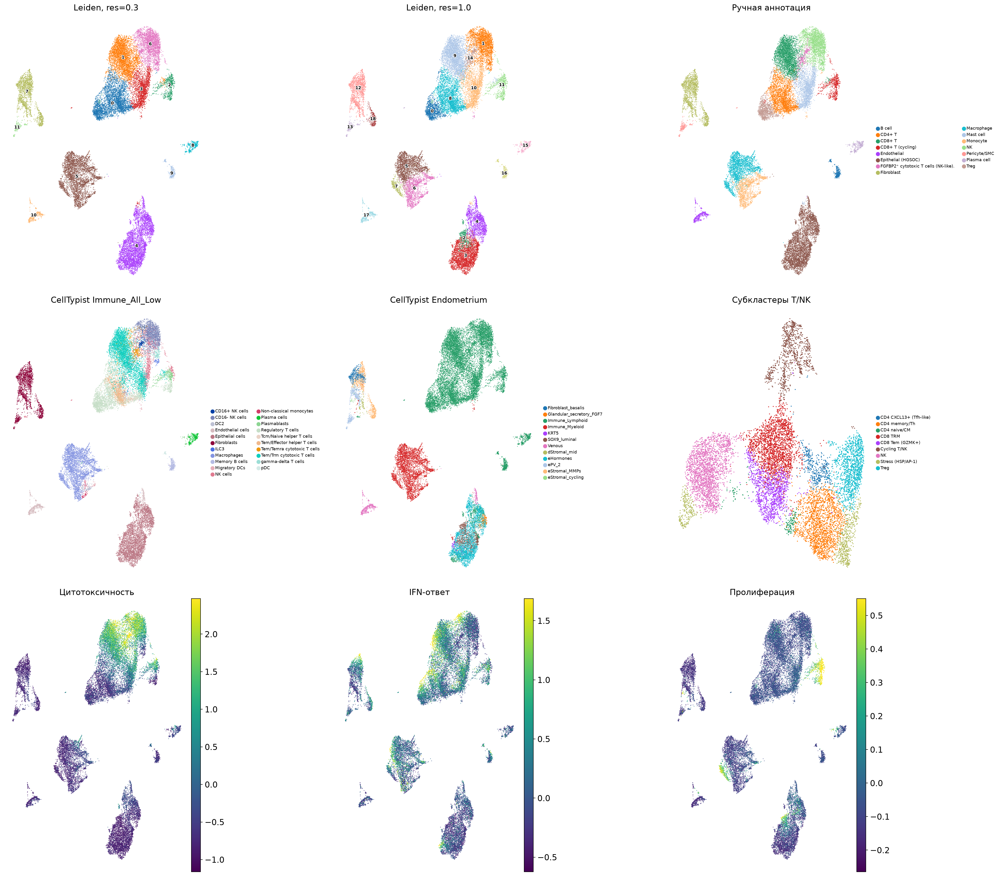

In [76]:
panels = [
    ("leiden_0.3", "Leiden, res=0.3", adata), ("leiden_1.0", "Leiden, res=1.0", adata),
    ("manual_cell_type", "Ручная аннотация", adata), ("ct_immune_mv", "CellTypist Immune_All_Low", adata),
    ("ct_endo_mv", "CellTypist Endometrium", adata), ("t_subtype", "Субкластеры T/NK", adata_t),
    ("cytotoxic_score", "Цитотоксичность", adata), ("ifn_score", "IFN-ответ", adata),
    ("prolif_score", "Пролиферация", adata),
]
fig, axes = plt.subplots(3, 3, figsize=(24, 21))
for ax, (key, title, obj) in zip(axes.flat, panels):
    categorical = obj.obs[key].dtype.name == "category"
    kw = dict(legend_loc="on data", legend_fontsize=7, legend_fontoutline=2) if key.startswith("leiden") \
        else dict(legend_fontsize=7) if categorical else dict(cmap="viridis", vmax="p99")
    sc.pl.umap(obj, color=key, ax=ax, show=False, title=title, frameon=False, **kw)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "summary_umaps.png", dpi=120, bbox_inches="tight")
plt.show()

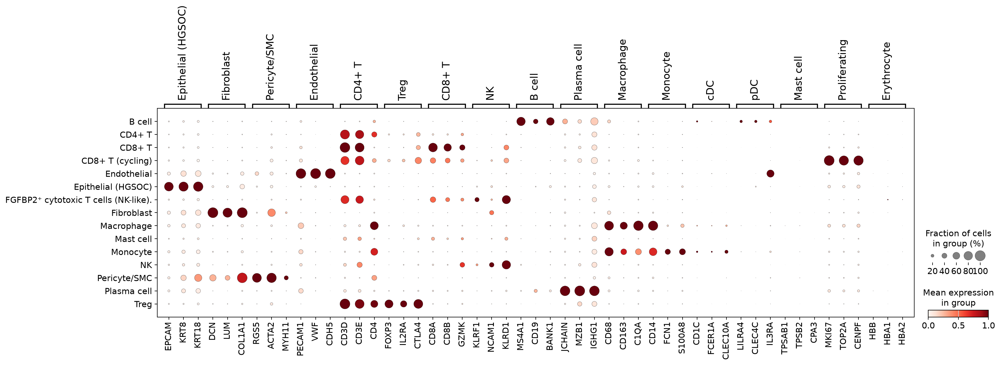

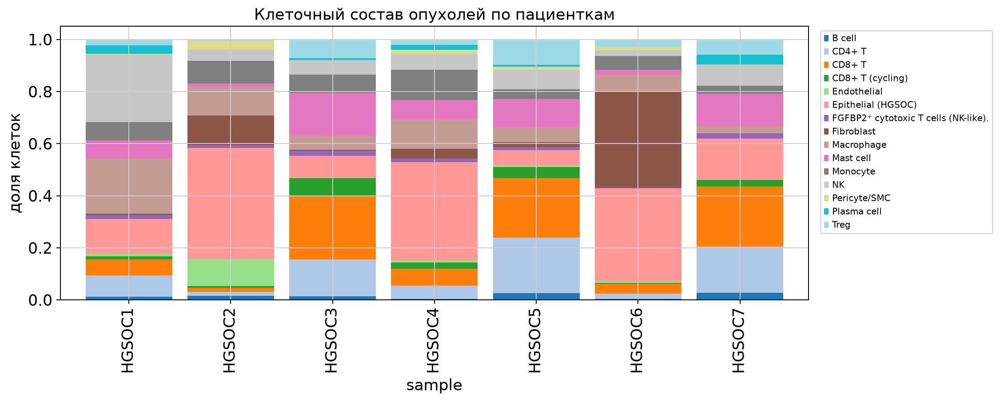

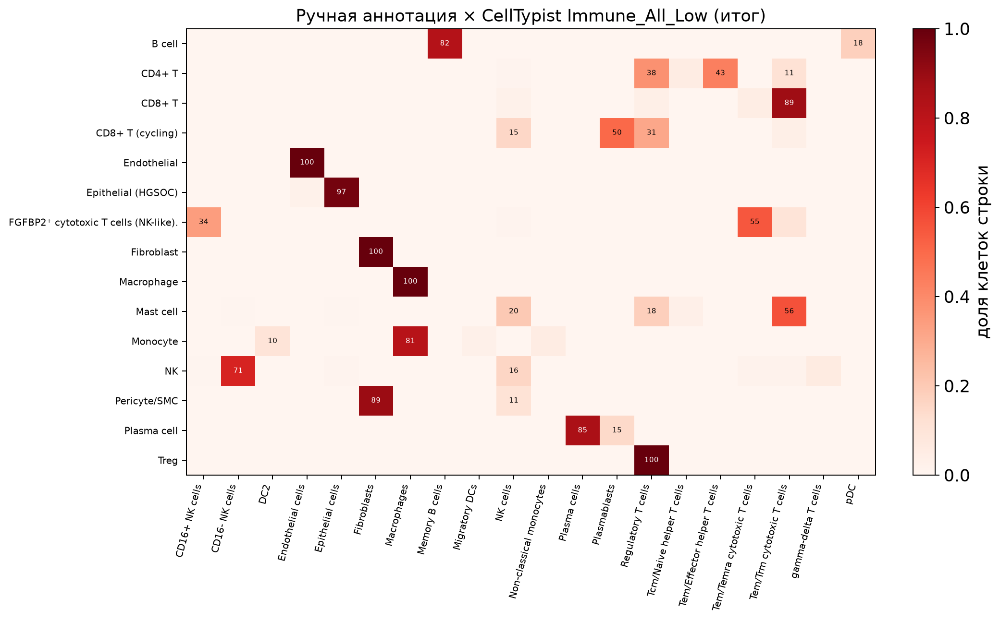

ct_immune_mv,CD16+ NK cells,CD16- NK cells,DC2,Endothelial cells,Epithelial cells,Fibroblasts,Macrophages,Memory B cells,Migratory DCs,NK cells,Non-classical monocytes,Plasma cells,Plasmablasts,Regulatory T cells,Tcm/Naive helper T cells,Tem/Effector helper T cells,Tem/Temra cytotoxic T cells,Tem/Trm cytotoxic T cells,gamma-delta T cells,pDC
manual_cell_type,,,,,,,,,,,,,,,,,,,,
B cell,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.822222,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.177778
CD4+ T,0.000000,0.000708,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.010981,0.00000,0.000000,0.000000,0.378675,0.051010,0.432164,0.000354,0.110875,0.000000,0.000000
CD8+ T,0.000000,0.003489,0.000291,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.026752,0.00000,0.000000,0.000000,0.035185,0.000000,0.000872,0.048270,0.885141,0.000000,0.000000
CD8+ T (cycling),0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.153627,0.00000,0.000000,0.500711,0.310100,0.000000,0.000000,0.000000,0.035562,0.000000,0.000000
Endothelial,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Epithelial (HGSOC),0.000000,0.000000,0.000000,0.025982,0.972233,0.000595,0.000198,0.000000,0.000000,0.000595,0.00000,0.000000,0.000000,0.000198,0.000000,0.000000,0.000000,0.000198,0.000000,0.000000
FGFBP2⁺ cytotoxic T cells (NK-like).,0.341737,0.002801,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.008403,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.549020,0.098039,0.000000,0.000000
Fibroblast,0.000000,0.000000,0.000000,0.001531,0.000510,0.997958,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Macrophage,0.000000,0.000000,0.000000,0.000000,0.000402,0.000000,0.997988,0.000000,0.000000,0.000000,0.00000,0.001610,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [77]:
SUMMARY_MARKERS = {t: gs[:3] for t, gs in canon_dot.items()}
sc.pl.dotplot(adata, var_names=SUMMARY_MARKERS, groupby="manual_cell_type", standard_scale="var",
              use_raw=False, show=False)
plt.savefig(RESULTS_DIR / "summary_dotplot.png", dpi=120, bbox_inches="tight")
plt.show()

comp_types = pd.crosstab(adata.obs["sample"], adata.obs["manual_cell_type"], normalize="index")
ax = comp_types.plot(kind="bar", stacked=True, figsize=(12, 4.5), width=0.85, colormap="tab20")
ax.set(ylabel="доля клеток", title="Клеточный состав опухолей по пациенткам")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.show()

plot_crosstab(adata.obs["manual_cell_type"], adata.obs["ct_immune_mv"],
              title="Ручная аннотация × CellTypist Immune_All_Low (итог)")

In [78]:
n_by_type = adata.obs["manual_cell_type"].value_counts()
n_by_comp = adata.obs["compartment"].value_counts(normalize=True)
print(f"Клеток после QC: {adata.n_obs}; образцов: {adata.obs['sample'].nunique()}")
print(f"Кластеров: res=0.3 -> {adata.obs['leiden_0.3'].nunique()}, res=1.0 -> {adata.obs['leiden_1.0'].nunique()}")
print("\nКомпартменты:", ", ".join(f"{k} {v:.0%}" for k, v in n_by_comp.items()))
print("Типы:", ", ".join(f"{k} ({v})" for k, v in n_by_type.items()))
print(f"\nСовпадение с CellTypist среди иммунных клеток: тип "
      f"{(manual_base[immune_mask] == adata.obs.loc[immune_mask, 'ct_immune_type'].astype(str)).mean():.0%}, "
      f"компартмент {(adata.obs.loc[immune_mask, 'compartment'].astype(str) == adata.obs.loc[immune_mask, 'ct_immune_compartment'].astype(str)).mean():.0%}")
print("Субтипы T/NK:", ", ".join(f"{k} ({v})" for k, v in adata_t.obs["t_subtype"].value_counts().items()))
for p in PROGRAMS:
    print(f"{PROGRAM_TITLES[p]}: максимум в «{prog_by_type[p].idxmax()}»")

Клеток после QC: 25901; образцов: 7
Кластеров: res=0.3 -> 12, res=1.0 -> 19

Компартменты: T/NK 42%, Epithelial 19%, Myeloid/DC 16%, Stromal 10%, Mast 9%, B/Plasma 3%, Other 1%
Типы: Epithelial (HGSOC) (5042), CD8+ T (3439), CD4+ T (2823), NK (2628), Macrophage (2485), Mast cell (2208), Fibroblast (1959), Monocyte (1557), Treg (1214), CD8+ T (cycling) (703), Endothelial (429), B cell (405), Plasma cell (400), FGFBP2⁺ cytotoxic T cells (NK-like). (357), Pericyte/SMC (252)

Совпадение с CellTypist среди иммунных клеток: тип 64%, компартмент 85%
Субтипы T/NK: NK (2135), CD8 TRM (2132), CD4 memory/Th (1822), CD8 Tem (GZMK+) (1248), Treg (1229), Cycling T/NK (943), Stress (HSP/AP-1) (738), CD4 CXCL13+ (Tfh-like) (390), CD4 naive/CM (170)
Цитотоксичность: максимум в «FGFBP2⁺ cytotoxic T cells (NK-like).»
IFN-ответ I типа: максимум в «CD8+ T»
Пролиферация (S+G2/M): максимум в «CD8+ T (cycling)»


### Заключение


1. **Основные клеточные популяции.** В опухолях HGSOC выделяются три крупных компартмента:
   - **эпителиальные/опухолевые клетки** (частично специфичные для пациенток кластеры);
   - **строма**: фибробласты/CAF, перициты и гладкомышечные клетки, эндотелий;
   - **иммунное микроокружение**: T/NK (CD4, Treg, CD8, NK), B и плазматические клетки, моноциты и макрофаги, cDC, pDC, тучные клетки.
2. **Маркеры.**
   - эпителий: `EPCAM`, `KRT8/18/19`, `PAX8`, `MUC16`;
   - фибробласты: `DCN`, `LUM`, `COL1A1/1A2/3A1`; перициты и ГМК: `RGS5`, `ACTA2`, `MYH11`; эндотелий: `PECAM1`, `VWF`, `CDH5`;
   - T: `CD3D/E` с `CD4`/`CD8A`; Treg: `FOXP3`, `CTLA4`; NK: `KLRF1`, `NCAM1`;
   - B: `MS4A1`, `CD19`; плазматические: `JCHAIN`, `MZB1`;
   - макрофаги: `C1QA/B/C`, `CD163`; моноциты: `S100A8/9`, `FCN1`; cDC: `CD1C`, `CLEC9A`; pDC: `LILRA4`; тучные: `TPSAB1`, `CPA3`.
3. **Согласие ручной и автоматической аннотации.** Для иммунных клеток аннотации хорошо согласуются на уровне компартментов и большинства типов (доли см. выше). Расхождения сосредоточены в неиммунных клетках, где у `Immune_All_Low` нет подходящих классов и низкая уверенность, и на плавных границах T-клеточных подтипов. Модель эндометрия правильно отделяет эпителий, строму и эндотелий, но называет опухолевый эпителий «нормальными» эндометриальными классами.
4. **Субкластеризация T/NK** выявила функциональные состояния, невидимые при общей кластеризации: наивные/CM CD4, Treg, CD8 Tem (`GZMK`⁺), CD8 TRM (`ITGAE`⁺), истощённые CD8 TEX (`PDCD1`⁺ `HAVCR2`⁺ `TIGIT`⁺ `CXCL13`⁺), NK и пролиферирующие клетки. Это согласуется со статьёй, где описаны CD8⁺ TRM и TEX с высоким `TIGIT`.
5. **Что дали генные программы.**
   - цитотоксичность локализует эффекторные CD8 и NK;
   - пролиферация показывает, что «cycling»-кластеры — делящиеся опухолевые и T-клетки, а не отдельный тип, и что доля делящихся опухолевых клеток различается между пациентками;
   - IFN-ответ выявляет ISG-high состояния и межопухолевую гетерогенность.

   Программы описывают состояние клетки поверх её типа и помогают не принимать состояние за новый тип.

**Ограничения и что можно сделать дальше:**
- злокачественность эпителия строго подтверждается только CNV-анализом (`infercnvpy`);
- субкластеризация миелоидных клеток и фибробластов (mCAF, iCAF) — следующий шаг;
- сравнение ранних и поздних стадий требует клинических метаданных, которых нет в именах файлов.